# SwiftRoute Logistics - Delivery Delay Prediction
## DSAI Mini Coursework

**Student name**: Vo Phan Vuong Hung 

**Email**: vpvh2005@gmail.com

**Discord username**: vpvh

**Submission date**: Wednesday, 21st October, 2026

| Section | Marks |
|---|---:|
| 1 | 10 |
| 2 | 3 |
| 3 | 10 |
| 4 | 12 |
| 5 | 15 |
| 6 | 15 |
| 7 | 8 |
| 8 | 12 |
| 9 | 5 |
| Extension | 10 |
| **Total** | **100** |

**Execution:** run all cells, in order. Raw CSVs are unchanged. Outputs are `figures/*.png`, `results.json`, `validation_predictions.csv` and `model.pkl`. Seed 42 is used throughout. All quantitative conclusions below are generated from the executed data, not entered in advance.

**Contract:** score one shipment at pickup, before network entry. Use an 80/20 stratified holdout and five shuffled stratified training folds. Route/carrier snapshots and recorded weather are assumed available at pickup; missing publication/snapshot timestamps make this assumption unverifiable. This is not proof of future-period performance or causal intervention effectiveness.

---
# SECTION 1 - Understanding the Problem *(10 marks)*

**1.1** SwiftRoute predicts whether a shipment will arrive outside its promised window, at pickup, so Operations can prioritise the highest-risk 15% for proactive intervention.

**1.2** This is binary classification: `is_delayed` is 1 for late delivery and 0 otherwise. One cleaned row represents one shipment, not a route or weather event.

**1.3** With roughly 12% delayed, always predicting on-time achieves roughly 88% accuracy while finding no delays. The primary metric is ROC-AUC: the probability that a randomly selected delayed shipment receives a higher risk score than a randomly selected on-time shipment (ties contribute half). It evaluates ranking across thresholds, not probability calibration. The operational metric is delay capture at the fixed 15% intervention capacity: the fraction of all actual delays among flagged shipments. Precision describes how much intervention capacity is spent on actual delays.

**1.4** A false positive flags an on-time shipment, using scarce staff/capacity and potentially incurring unnecessary upgrade costs. A false negative misses a delay, losing an opportunity to avoid an SLA penalty and customer harm. A missed delay can be more damaging per case, but no intervention cost or prevention effectiveness is supplied, so the economically optimal trade-off cannot be established. At fixed capacity, each unnecessary flag can displace a useful intervention.

**1.5** An equality join on dates is insufficient: match the origin and destination independently to events in the same region where `start_date <= pickup_date <= end_date`. Multiple overlapping events must first be aggregated to maximum severity per shipment/end; otherwise a many-to-many join duplicates shipments. No match is encoded as zero recorded severity, not proof that no disruption occurred.

---
# SECTION 2 - Setup & Data Loading *(3 marks)*

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

RANDOM_STATE = 42
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
report = {'execution_utc': datetime.now(timezone.utc).isoformat(), 'seed': RANDOM_STATE,
          'assumptions': ['Repeated raw inputs denote repeated shipment records; labels checked separately.',
                          'Supplied route/carrier snapshots and weather assumed available at pickup; timestamps absent.',
                          'Gross benefit assumes 100% prevention and excludes intervention costs.']}
figure_files = []
def show_figure(name):
    path = FIGURES / (name + '.png')
    plt.savefig(path, dpi=150, bbox_inches='tight')
    figure_files.append(str(path))
    plt.show()
    plt.close()
def records(frame):
    return json.loads(frame.to_json(orient='records', date_format='iso'))
def answer(text):
    display(Markdown(text))

In [2]:
shipments = pd.read_csv('data/shipments.csv', parse_dates=['pickup_date'])
routes = pd.read_csv('data/routes.csv')
carriers = pd.read_csv('data/carriers.csv')
weather = pd.read_csv('data/weather_events.csv', parse_dates=['start_date', 'end_date'])
for name, frame in [('shipments', shipments), ('routes', routes), ('carriers', carriers), ('weather', weather)]:
    print(f'{name}: {frame.shape[0]:,} rows, {frame.shape[1]} columns')
    display(frame.head())

shipments: 10,025 rows, 12 columns


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0


routes: 60 rows, 7 columns


,route_id,origin_region,dest_region,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days
0,R0001,London,North_East,480,3,0.2471,2.92
1,R0002,Scotland,Yorkshire,139,1,0.1617,1.85
2,R0003,South_West,Midlands,191,1,0.1449,1.71
3,R0004,London,South_East,127,1,0.0450,1.85
4,R0005,Midlands,North_East,279,2,0.0970,1.96


carriers: 8 rows, 7 columns


,carrier_id,carrier_name,tier_coverage,reliability_score,capacity_utilisation,avg_delay_mins,n_active_routes
0,C01,FastTrack,all,0.9508,0.5926,78.2,17
1,C02,PrimeMove,all,0.9049,0.6838,82.2,25
2,C03,SureDeliver,all,0.8605,0.6675,35.0,8
3,C04,QuickHaul,all,0.8332,0.7361,29.7,11
4,C05,NorthernPost,express_only,0.7640,0.8150,34.9,15


weather: 265 rows, 6 columns


,event_id,region,event_type,severity,start_date,end_date
0,W00001,Midlands,high_wind,2,2024-01-03,2024-01-05
1,W00002,Yorkshire,snow,1,2024-01-26,2024-01-30
2,W00003,London,flood,1,2024-01-15,2024-01-18
3,W00004,North_East,high_wind,1,2024-01-26,2024-02-01
4,W00005,North_West,storm,2,2024-01-24,2024-01-26


---
# SECTION 3 - Exploring the Data (EDA) *(10 marks)*
### 3.1 Data Quality Check *(3 marks)*

In [3]:
# Define equality using raw inputs only; the label must never define duplicate identity.
input_cols = [c for c in shipments if c not in ['shipment_id', 'is_delayed']]
label_counts = shipments.groupby(input_cols, dropna=False)['is_delayed'].nunique(dropna=False)
assert label_counts.max() == 1, 'Conflicting labels in repeated-input groups; investigate before deduplication.'
assert shipments['is_delayed'].isin([0, 1]).all()
assert shipments['pickup_date'].notna().all()
assert routes['route_id'].is_unique and carriers['carrier_id'].is_unique
assert weather['event_id'].is_unique
assert weather[['start_date', 'end_date', 'region', 'severity']].notna().all().all()
assert weather['start_date'].le(weather['end_date']).all()
assert weather['severity'].isin([1, 2, 3]).all()
quality = {}
for name, frame in [('shipments', shipments), ('routes', routes), ('carriers', carriers), ('weather', weather)]:
    table = pd.DataFrame({'dtype': frame.dtypes.astype(str), 'nulls': frame.isna().sum()})
    print(name)
    display(table)
    quality[name] = {'shape': list(frame.shape), 'columns': records(table.reset_index(names='column'))}
quality.update(raw_rows=len(shipments), exact_repeats=int(shipments.duplicated().sum()),
               repeated_inputs=int(shipments.duplicated(input_cols).sum()),
               repeated_ids=int(shipments['shipment_id'].duplicated().sum()),
               conflicting_label_groups=int((label_counts > 1).sum()),
               missing_route_ids=int((~shipments.route_id.isin(routes.route_id)).sum()),
               missing_carrier_ids=int((~shipments.carrier_id.isin(carriers.carrier_id)).sum()),
               raw_delays=int(shipments.is_delayed.sum()), raw_delay_rate=float(shipments.is_delayed.mean()),
               pickup_start=str(shipments.pickup_date.min().date()), pickup_end=str(shipments.pickup_date.max().date()),
               weather_start=str(weather.start_date.min().date()), weather_end=str(weather.end_date.max().date()))
print(json.dumps({k: v for k, v in quality.items() if not isinstance(v, dict)}, indent=2))
report['quality'] = quality

# Deterministic lookup joins use no labels; reusable for EDA and the final master table.
route_fields = ['distance_km', 'n_depot_hops', 'historical_delay_rate', 'avg_transit_days']
carrier_fields = ['reliability_score', 'capacity_utilisation']
def join_lookups(frame):
    out = frame.merge(routes[['route_id'] + route_fields], on='route_id', how='left', validate='many_to_one')
    out = out.merge(carriers[['carrier_id'] + carrier_fields], on='carrier_id', how='left', validate='many_to_one')
    assert len(out) == len(frame)
    return out

def add_weather(frame, events):
    out = frame.copy()
    for end, region_col in [('origin', 'origin_region'), ('dest', 'dest_region')]:
        severity = np.zeros(len(out), dtype=np.int64)
        for event in events.itertuples(index=False):
            mask = (out[region_col].eq(event.region) & out['pickup_date'].between(event.start_date, event.end_date, inclusive='both')).to_numpy()
            severity[mask] = np.maximum(severity[mask], event.severity)
        out[end + '_weather_severity'] = severity
    return out

# Full-population summaries below are descriptive only, not inputs to model selection.
eda = add_weather(join_lookups(shipments.drop_duplicates(input_cols, keep='first')), weather)
eda['weather_affected'] = ((eda.origin_weather_severity > 0) | (eda.dest_weather_severity > 0)).astype(int)
assert len(eda) == 10000 and int(eda.is_delayed.sum()) == 1191
report['quality']['clean_rows'] = len(eda)
report['quality']['clean_delays'] = int(eda.is_delayed.sum())
report['quality']['clean_delay_rate'] = float(eda.is_delayed.mean())

shipments


,dtype,nulls
shipment_id,str,0
pickup_date,datetime64[us],0
origin_region,str,0
dest_region,str,0
service_tier,str,0
carrier_id,str,0
route_id,str,0
weight_kg,float64,320
volume_cm3,int64,0
declared_value,float64,507


routes


,dtype,nulls
route_id,str,0
origin_region,str,0
dest_region,str,0
distance_km,int64,0
n_depot_hops,int64,0
historical_delay_rate,float64,0
avg_transit_days,float64,0


carriers


,dtype,nulls
carrier_id,str,0
carrier_name,str,0
tier_coverage,str,0
reliability_score,float64,0
capacity_utilisation,float64,0
avg_delay_mins,float64,0
n_active_routes,int64,0


weather


,dtype,nulls
event_id,str,0
region,str,0
event_type,str,0
severity,int64,0
start_date,datetime64[us],0
end_date,datetime64[us],0


{
  "raw_rows": 10025,
  "exact_repeats": 0,
  "repeated_inputs": 25,
  "repeated_ids": 0,
  "conflicting_label_groups": 0,
  "missing_route_ids": 0,
  "missing_carrier_ids": 0,
  "raw_delays": 1194,
  "raw_delay_rate": 0.11910224438902743,
  "pickup_start": "2024-01-01",
  "pickup_end": "2026-06-19",
  "weather_start": "2024-01-03",
  "weather_end": "2026-06-01"
}


**Commentary.** Duplicate identity is an explicit assumption: equal raw shipment inputs, excluding ID and label, represent a repeated record. Labels are checked for agreement first; keep the first such record. Unique IDs alone cannot detect copies assigned new IDs. The quality output reports every null and foreign-key gap rather than assuming complete data. Missing numeric predictors will be median-imputed and categorical predictors imputed/encoded inside each training-fold pipeline; unmatched weather is zero recorded severity. Missing labels/dates, conflicting duplicate labels or nonunique lookup keys stop execution. Supplied route `historical_delay_rate` is documented as past-derived and valid; the dates of its snapshot, `avg_transit_days` and carrier snapshots are nevertheless unavailable, so pickup-time availability cannot be verified. Weather coverage dates do not establish complete event reporting or forecast availability. EDA uses the deduplicated descriptive population; the formal cleaning step below reproduces it.

### 3.2 Distribution of Key Columns *(2 marks)*

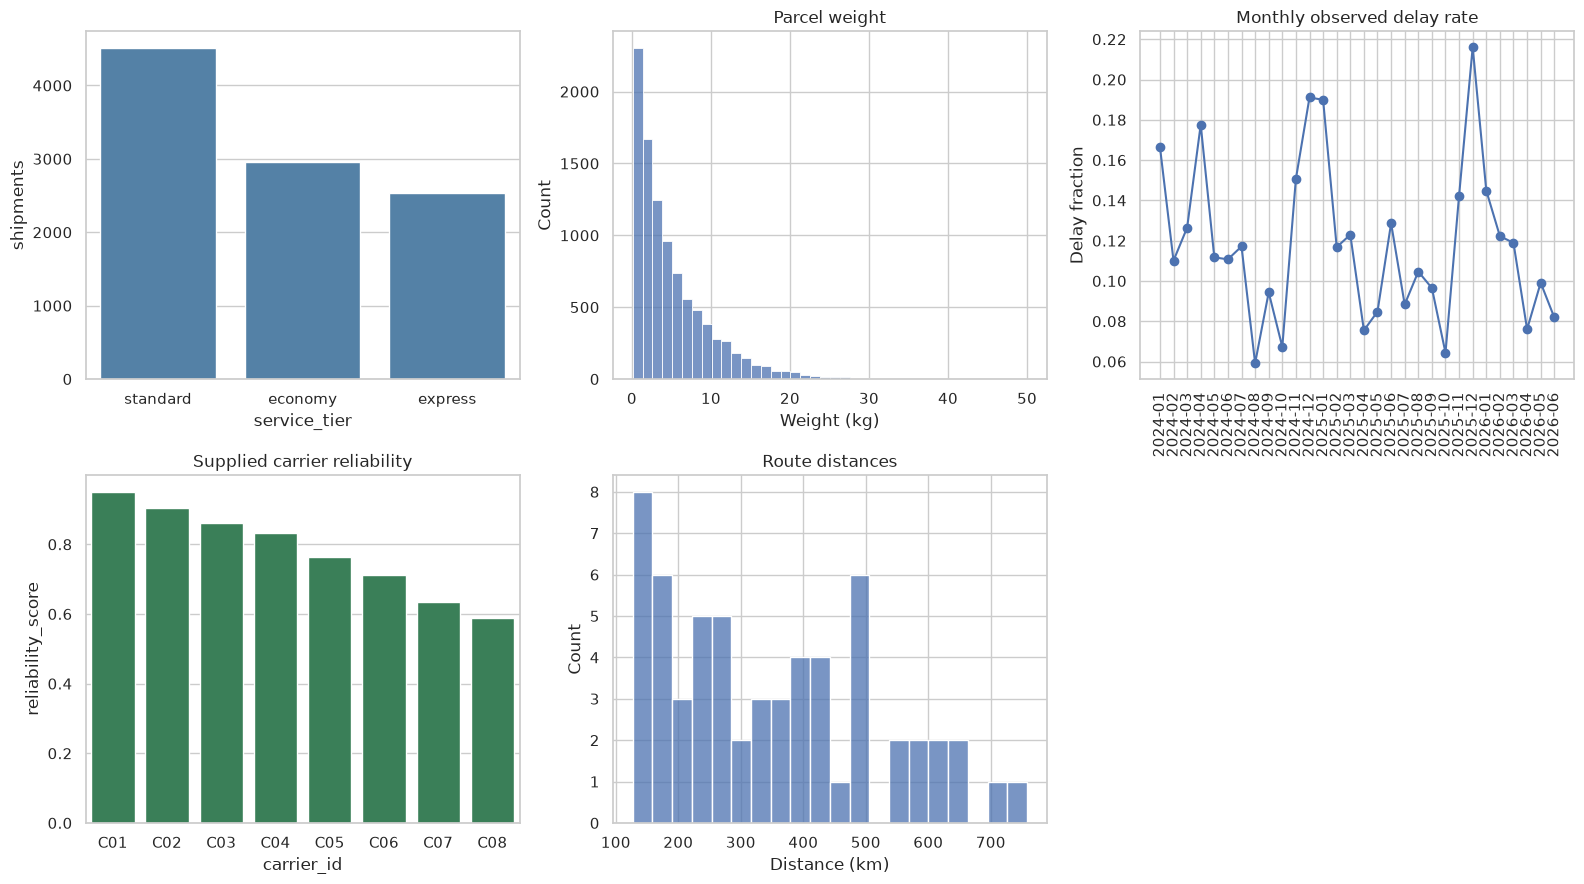

**Observed distributions:** standard is the largest tier (4,512 shipments). Monthly delay rates range from 5.9% to 21.6%; monthly counts range from 232 to 374, so rate variation alone does not establish a time trend. The final month may cover only part of a month.

In [4]:
tier_mix = eda.service_tier.value_counts().rename_axis('service_tier').reset_index(name='shipments')
monthly = eda.groupby(eda.pickup_date.dt.to_period('M'))['is_delayed'].agg(n='size', delays='sum', delay_rate='mean').reset_index()
monthly['pickup_date'] = monthly.pickup_date.astype(str)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.barplot(data=tier_mix, x='service_tier', y='shipments', ax=axes[0, 0], color='steelblue')
sns.histplot(eda.weight_kg, bins=40, ax=axes[0, 1])
axes[0, 1].set(title='Parcel weight', xlabel='Weight (kg)')
axes[0, 2].plot(monthly.pickup_date, monthly.delay_rate, marker='o')
axes[0, 2].tick_params(axis='x', rotation=90)
axes[0, 2].set(title='Monthly observed delay rate', ylabel='Delay fraction')
sns.barplot(data=carriers, x='carrier_id', y='reliability_score', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Supplied carrier reliability')
sns.histplot(routes.distance_km, bins=20, ax=axes[1, 1])
axes[1, 1].set(title='Route distances', xlabel='Distance (km)')
axes[1, 2].axis('off')
fig.tight_layout()
show_figure('eda_distributions')
report['eda'] = {'service_mix': records(tier_mix), 'monthly': records(monthly)}
answer(f'**Observed distributions:** {tier_mix.iloc[0].service_tier} is the largest tier ({int(tier_mix.iloc[0].shipments):,} shipments). Monthly delay rates range from {monthly.delay_rate.min():.1%} to {monthly.delay_rate.max():.1%}; monthly counts range from {monthly.n.min()} to {monthly.n.max()}, so rate variation alone does not establish a time trend. The final month may cover only part of a month.')

**Commentary — two observations.** The executed commentary above identifies the largest service tier and the observed range of monthly delay rates, with denominators. Weight and distance are shown as distributions rather than only means because long tails can affect handling and routing. Differences in time, tier or carrier are associations and may reflect different shipment mixes.

### 3.3 Which Factors Are Related to Delays? *(3 marks)*

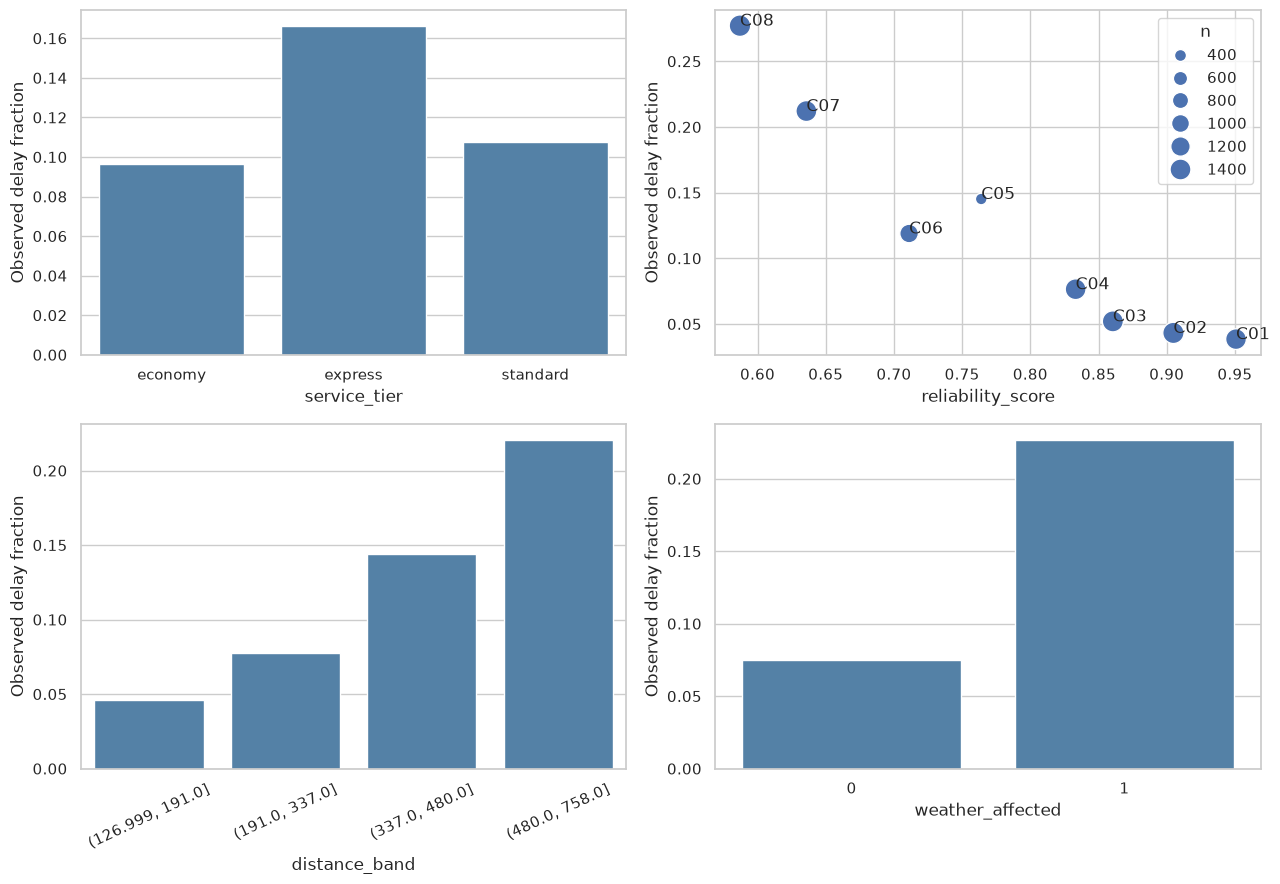

,service_tier,n,delays,delay_rate
0,economy,2958,285,0.096349
1,express,2530,420,0.166008
2,standard,4512,486,0.107713


,carrier_id,n,delays,delay_rate,carrier_name,reliability_score
0,C01,1377,53,0.038489,FastTrack,0.9508
1,C02,1458,63,0.043210,PrimeMove,0.9049
2,C03,1423,74,0.052003,SureDeliver,0.8605
3,C04,1386,106,0.076479,QuickHaul,0.8332
4,C05,372,54,0.145161,NorthernPost,0.7640
5,C06,1085,129,0.118894,IslandEx,0.7111
6,C07,1405,298,0.212100,GreenRoute,0.6358
7,C08,1494,414,0.277108,BudgetShip,0.5871


,distance_band,n,delays,delay_rate
0,"(126.999, 191.0]",2509,115,0.045835
1,"(191.0, 337.0]",2493,194,0.077818
2,"(337.0, 480.0]",2865,412,0.143805
3,"(480.0, 758.0]",2133,470,0.220347


,weather_affected,n,delays,delay_rate
0,0,7087,531,0.074926
1,1,2913,660,0.226571


**Observed strongest relationships:** carrier: 23.9 percentage-point rate spread; distance quartile: 17.5 percentage-point rate spread; recorded weather: 15.2 percentage-point rate spread; service tier: 7.0 percentage-point rate spread. These descriptive spreads depend on grouping granularity and confounding; they are not causal effect sizes or holdout tuning criteria.

In [5]:
def delay_summary(frame, keys):
    return frame.groupby(keys, dropna=False, observed=True)['is_delayed'].agg(n='size', delays='sum', delay_rate='mean').reset_index()
service_rates = delay_summary(eda, 'service_tier')
carrier_rates = delay_summary(eda, 'carrier_id').merge(carriers[['carrier_id', 'carrier_name', 'reliability_score']], on='carrier_id', validate='one_to_one')
eda['distance_band'] = pd.qcut(eda.distance_km, q=4, duplicates='drop')
distance_rates = delay_summary(eda, 'distance_band')
distance_rates['distance_band'] = distance_rates.distance_band.astype(str)
weather_rates = delay_summary(eda, 'weather_affected')
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(data=service_rates, x='service_tier', y='delay_rate', ax=axes[0, 0], color='steelblue')
sns.scatterplot(data=carrier_rates, x='reliability_score', y='delay_rate', size='n', sizes=(70, 240), ax=axes[0, 1])
for row in carrier_rates.itertuples():
    axes[0, 1].annotate(row.carrier_id, (row.reliability_score, row.delay_rate))
sns.barplot(data=distance_rates, x='distance_band', y='delay_rate', ax=axes[1, 0], color='steelblue')
axes[1, 0].tick_params(axis='x', rotation=25)
sns.barplot(data=weather_rates, x='weather_affected', y='delay_rate', ax=axes[1, 1], color='steelblue')
for ax in axes.flat:
    ax.set_ylabel('Observed delay fraction')
fig.tight_layout()
show_figure('eda_delay_relationships')
for table in [service_rates, carrier_rates, distance_rates, weather_rates]:
    display(table)
spreads = {name: float(table.delay_rate.max() - table.delay_rate.min()) for name, table in [('service tier', service_rates), ('carrier', carrier_rates), ('distance quartile', distance_rates), ('recorded weather', weather_rates)]}
report['eda'].update(service_rates=records(service_rates), carrier_rates=records(carrier_rates), distance_rates=records(distance_rates), weather_rates=records(weather_rates), rate_spreads=spreads)
ordered_spreads = sorted(spreads.items(), key=lambda item: item[1], reverse=True)
answer('**Observed strongest relationships:** ' + '; '.join(f'{name}: {spread * 100:.1f} percentage-point rate spread' for name, spread in ordered_spreads) + '. These descriptive spreads depend on grouping granularity and confounding; they are not causal effect sizes or holdout tuning criteria.')

**Commentary.** The generated ranking above compares observed differences in delay rate; tables supply denominators. Carrier reliability is plotted against realised carrier delay rates to check whether the historical score aligns with outcomes. Distance quartiles avoid treating every distinct distance as equally well-supported. Weather associations depend on the supplied event register: zero means no recorded match. The strongest marginal relationship need not be the strongest conditional model feature.

### 3.4 Which Routes and Carriers Are Riskiest? *(2 marks)*

Highest observed route rates:


,route_id,n,delays,delay_rate,origin_region,dest_region
25,R0026,177,62,0.350282,London,Wales
36,R0037,156,48,0.307692,Wales,London
54,R0055,178,54,0.303371,Wales,South_East
42,R0043,164,43,0.262195,London,Scotland
14,R0015,177,41,0.231638,London,Yorkshire
0,R0001,194,41,0.211340,London,North_East
17,R0018,149,31,0.208054,Yorkshire,South_East
5,R0006,165,34,0.206061,Yorkshire,South_West
51,R0052,172,35,0.203488,Yorkshire,London
8,R0009,160,32,0.200000,South_East,North_East


Carrier rates:


,carrier_id,n,delays,delay_rate,carrier_name,reliability_score
7,C08,1494,414,0.277108,BudgetShip,0.5871
6,C07,1405,298,0.212100,GreenRoute,0.6358
4,C05,372,54,0.145161,NorthernPost,0.7640
5,C06,1085,129,0.118894,IslandEx,0.7111
3,C04,1386,106,0.076479,QuickHaul,0.8332
2,C03,1423,74,0.052003,SureDeliver,0.8605
1,C02,1458,63,0.043210,PrimeMove,0.9049
0,C01,1377,53,0.038489,FastTrack,0.9508


Highest route/carrier combinations, all groups (including sparse groups):


,route_id,carrier_id,n,delays,delay_rate
335,R0042,C08,21,15,0.714286
340,R0043,C05,7,5,0.714286
205,R0026,C06,18,12,0.666667
206,R0026,C07,23,14,0.608696
343,R0043,C08,25,15,0.600000
118,R0015,C07,19,11,0.578947
295,R0037,C08,26,15,0.576923
143,R0018,C08,21,12,0.571429
207,R0026,C08,25,14,0.560000
119,R0015,C08,24,13,0.541667


Two highest combinations with at least 30 shipments (descriptive reporting threshold):


,route_id,carrier_id,n,delays,delay_rate
7,R0001,C08,30,16,0.533333
439,R0055,C08,32,14,0.437500


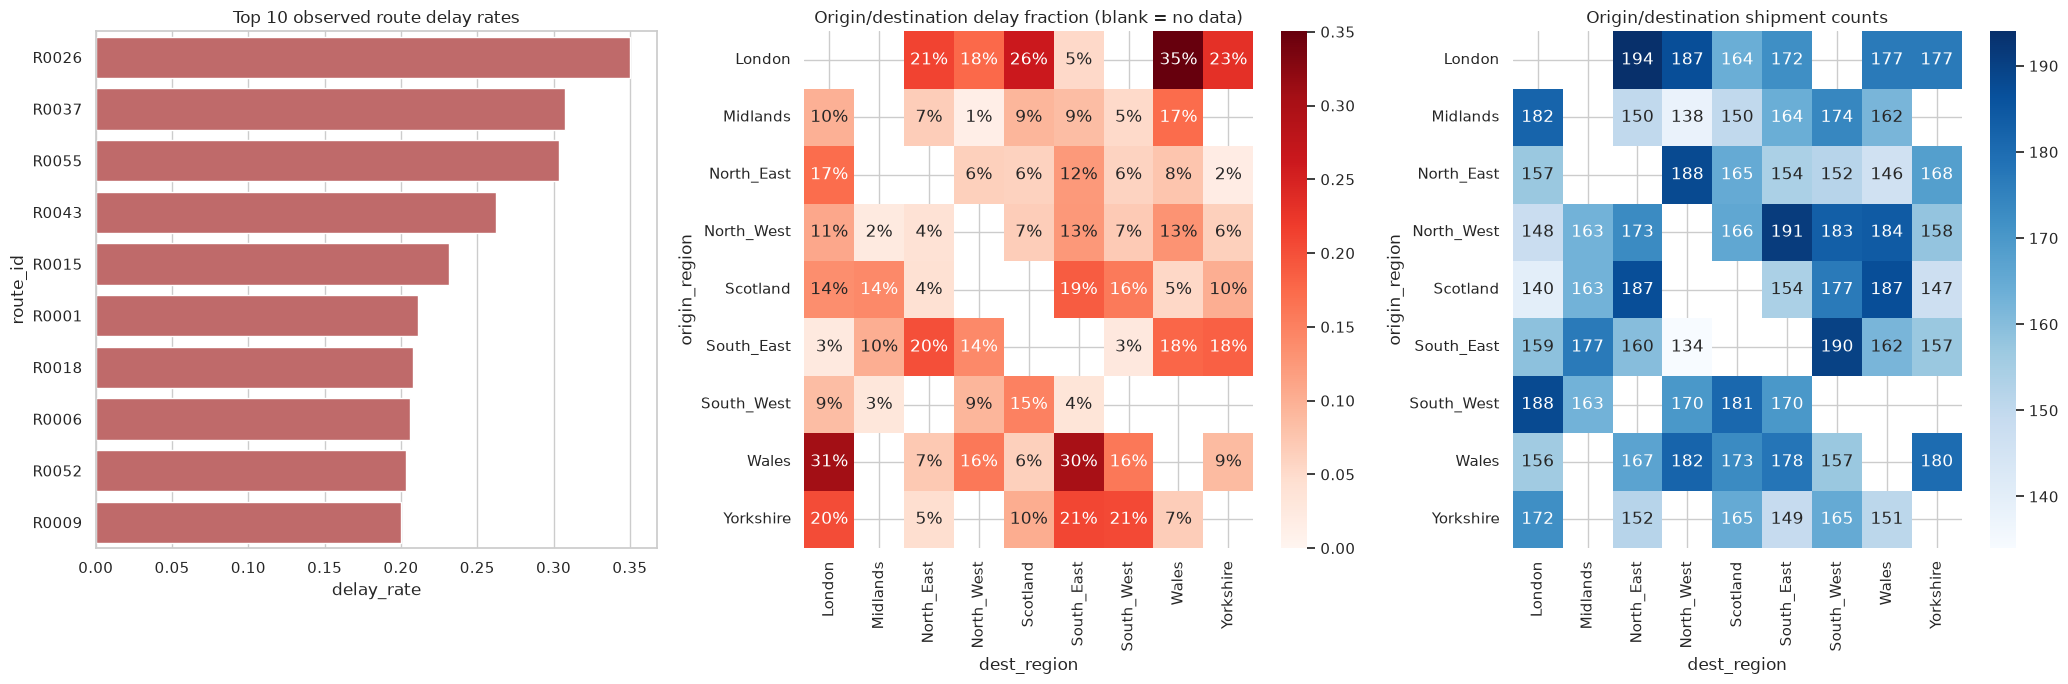

**Risky combinations:** R0001/C08: 53.3% (16/30); R0055/C08: 43.8% (14/32). These are the two largest observed rates among groups with at least 30 shipments, not statistically established worst routes. The all-group ranking is also shown so sparse extreme rates are visible. Operations should audit capacity, depot handoffs and service mix before reallocating carriers; a route/carrier association does not prove the carrier caused the delay.

In [6]:
route_rates = delay_summary(eda, 'route_id').merge(routes[['route_id', 'origin_region', 'dest_region']], on='route_id', validate='one_to_one')
top_routes = route_rates.sort_values(['delay_rate', 'n', 'route_id'], ascending=[False, False, True]).head(10)
combinations = delay_summary(eda, ['route_id', 'carrier_id']).sort_values(['delay_rate', 'n', 'route_id', 'carrier_id'], ascending=[False, False, True, True])
supported_combinations = combinations.loc[combinations.n >= 30].head(2)
print('Highest observed route rates:')
display(top_routes)
print('Carrier rates:')
display(carrier_rates.sort_values('delay_rate', ascending=False))
print('Highest route/carrier combinations, all groups (including sparse groups):')
display(combinations.head(10))
print('Two highest combinations with at least 30 shipments (descriptive reporting threshold):')
display(supported_combinations)
region_rates = delay_summary(eda, ['origin_region', 'dest_region'])
rate_matrix = region_rates.pivot(index='origin_region', columns='dest_region', values='delay_rate')
count_matrix = region_rates.pivot(index='origin_region', columns='dest_region', values='n')
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
sns.barplot(data=top_routes, x='delay_rate', y='route_id', ax=axes[0], color='indianred')
axes[0].set_title('Top 10 observed route delay rates')
sns.heatmap(rate_matrix, annot=True, fmt='.0%', cmap='Reds', ax=axes[1], vmin=0)
axes[1].set_title('Origin/destination delay fraction (blank = no data)')
sns.heatmap(count_matrix, annot=True, fmt='.0f', cmap='Blues', ax=axes[2])
axes[2].set_title('Origin/destination shipment counts')
fig.tight_layout()
show_figure('eda_route_carrier_risk')
report['eda'].update(top_routes=records(top_routes), route_carrier_combinations=records(combinations), supported_top_combinations=records(supported_combinations), region_rates=records(region_rates))
answer('**Risky combinations:** ' + '; '.join(f'{r.route_id}/{r.carrier_id}: {r.delay_rate:.1%} ({r.delays}/{r.n})' for r in supported_combinations.itertuples()) + '. These are the two largest observed rates among groups with at least 30 shipments, not statistically established worst routes. The all-group ranking is also shown so sparse extreme rates are visible. Operations should audit capacity, depot handoffs and service mix before reallocating carriers; a route/carrier association does not prove the carrier caused the delay.')

**Commentary.** The executed output names the two riskier supported route/carrier combinations and their counts; the threshold of 30 is a transparent descriptive stability screen, not a confidence guarantee. The count heatmap prevents treating a thin origin–destination cell as equally reliable as a well-used corridor. High-risk corridors are priorities for operational review rather than automatic network closure.

---
# SECTION 4 - Cleaning & Joining the Data *(12 marks)*

In [7]:
# 4.1 Keep first record of each repeated raw-input group, after label agreement check.
clean_shipments = shipments.drop_duplicates(input_cols, keep='first').copy().reset_index(drop=True)
assert len(clean_shipments) == 10000 and clean_shipments.is_delayed.sum() == 1191
assert clean_shipments.shipment_id.is_unique
print(f'Removed {len(shipments) - len(clean_shipments)} repeated-input records; retained {len(clean_shipments):,}.')
display(clean_shipments.is_delayed.value_counts().rename_axis('is_delayed').to_frame('shipments'))

Removed 25 repeated-input records; retained 10,000.


,shipments
is_delayed,
0,8809
1,1191


In [8]:
# 4.2 Explicit fields avoid duplicate region columns and accidental outcome proxies.
master = join_lookups(clean_shipments)
print('Missing joined numeric fields:')
display(master[route_fields + carrier_fields].isna().sum().to_frame('nulls'))
# The two region definitions should agree wherever a route exists.
route_check = clean_shipments.merge(routes[['route_id', 'origin_region', 'dest_region']], on='route_id', how='left', suffixes=('_shipment', '_route'), validate='many_to_one')
matched = route_check.origin_region_route.notna()
assert route_check.loc[matched, 'origin_region_shipment'].eq(route_check.loc[matched, 'origin_region_route']).all()
assert route_check.loc[matched, 'dest_region_shipment'].eq(route_check.loc[matched, 'dest_region_route']).all()
assert len(master) == len(clean_shipments)

Missing joined numeric fields:


,nulls
distance_km,0
n_depot_hops,0
historical_delay_rate,0
avg_transit_days,0
reliability_score,0
capacity_utilisation,0


In [9]:
# 4.3 Inclusive interval matching with maximum severity independently at each end.
# Iterating the small event register avoids a shipment-by-event Cartesian join.
master = add_weather(master, weather)
assert len(master) == len(clean_shipments) and master.shipment_id.is_unique
coverage = master.groupby(['origin_weather_severity', 'dest_weather_severity']).size().rename('shipments').reset_index()
display(coverage)
report['weather_coverage'] = records(coverage)
answer(f'Weather register covers {weather.start_date.min().date()} to {weather.end_date.max().date()}; pickups cover {master.pickup_date.min().date()} to {master.pickup_date.max().date()}. Outside a recorded interval, severity is zero. Overlaps take the maximum, not a sum; origin and destination effects remain separate. Historical realised weather is used under the explicit pickup-availability assumption; operational use needs pickup-time observations or forecasts and timestamped snapshots.')

,origin_weather_severity,dest_weather_severity,shipments
0,0,0,7087
1,0,1,576
2,0,2,458
3,0,3,324
4,1,0,557
5,1,1,47
6,1,2,40
7,1,3,17
8,2,0,408
9,2,1,49


Weather register covers 2024-01-03 to 2026-06-01; pickups cover 2024-01-01 to 2026-06-19. Outside a recorded interval, severity is zero. Overlaps take the maximum, not a sum; origin and destination effects remain separate. Historical realised weather is used under the explicit pickup-availability assumption; operational use needs pickup-time observations or forecasts and timestamped snapshots.

---
# SECTION 5 - Creating New Features *(15 marks)*

In [10]:
def safe_volume_to_weight(volume, weight):
    # Missing/nonpositive weights and negative/missing volumes yield NaN for fold-fitted imputation.
    valid = weight.gt(0) & volume.ge(0) & np.isfinite(weight) & np.isfinite(volume)
    ratio = volume.where(valid).div(weight.where(valid))
    return ratio.replace([np.inf, -np.inf], np.nan)

# Any recorded disruption can affect handling at either endpoint.
master['weather_affected'] = ((master.origin_weather_severity > 0) | (master.dest_weather_severity > 0)).astype(int)
# Simultaneous endpoint disruption may compound network bottlenecks.
master['weather_both_ends'] = ((master.origin_weather_severity > 0) & (master.dest_weather_severity > 0)).astype(int)
# Winter can capture seasonal demand and disruption patterns available at pickup.
master['is_winter'] = master.pickup_date.dt.month.isin([11, 12, 1, 2]).astype(int)
# Bulkiness per kg is a handling proxy; invalid division stays missing for fold imputation.
master['volume_to_weight'] = safe_volume_to_weight(master.volume_cm3, master.weight_kg)
# Categorical weekdays capture operational schedules without a linear weekday assumption.
master['day_of_week'] = master.pickup_date.dt.dayofweek.astype(str)
# Cross-region movement can imply additional handoffs beyond local delivery.
master['is_cross_region'] = master.origin_region.ne(master.dest_region).astype(int)
# Unreliability interacts with historical route risk, with an interpretable direction.
master['carrier_route_risk'] = (1 - master.reliability_score) * master.historical_delay_rate
feature_preview = ['weather_affected', 'weather_both_ends', 'is_winter', 'volume_to_weight', 'day_of_week', 'is_cross_region', 'carrier_route_risk']
display(master[['shipment_id'] + feature_preview].head())

,shipment_id,weather_affected,weather_both_ends,is_winter,volume_to_weight,day_of_week,is_cross_region,carrier_route_risk
0,SH0000001,1,0,0,816.897747,4,1,0.027886
1,SH0000002,0,0,1,1065.226782,0,1,0.004644
2,SH0000003,0,0,1,223.255814,5,1,0.023553
3,SH0000004,1,0,0,739.932127,3,1,0.075354
4,SH0000005,0,0,0,446.756757,5,1,0.018114


**Feature explanations (more than five).**

| Feature | Meaning and reason |
|---|---|
| `origin_weather_severity`, `dest_weather_severity` | Maximum recorded disruption (0–3) at each endpoint; possible pickup/depot/delivery disruption. |
| `weather_affected` | Any endpoint has recorded weather; allows a binary disruption effect. |
| `weather_both_ends` | Both endpoints affected; simultaneous bottlenecks may be more damaging. |
| `is_winter` | Pickup in November–February; possible seasonal demand/weather disruption. Not evidence of a causal season effect. |
| `volume_to_weight` | cm³/kg, a bulky/light parcel proxy; awkward handling may cause delay. Nonpositive/missing weight or invalid volume gives NaN, never infinity. |
| `day_of_week` | Monday=0 through Sunday=6, categorical rather than a linear ordering; captures collection schedules/weekend exposure. |
| `is_cross_region` | Different origin/destination; potential extra handoffs. |
| `carrier_route_risk` | `(1 − reliability_score) × historical_delay_rate`; combines poorer carrier reliability with historically risky routes. Multiplying reliability itself would make the direction harder to interpret. |

Deterministic features use no target. IDs and raw pickup dates remain for audit, not predictors. Snapshot fields are used under the documented availability assumption. Learned imputation, scaling and category fitting are inside CV pipelines. Correlated weather and risk features are acceptable for prediction but make individual feature attributions nonunique.

---
# SECTION 6 - Training Models *(15 marks)*

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

base_numeric = ['weight_kg', 'volume_cm3', 'declared_value', 'is_business'] + route_fields + carrier_fields
base_categorical = ['service_tier']
enriched_numeric = base_numeric + ['origin_weather_severity', 'dest_weather_severity', 'weather_affected',
                                     'weather_both_ends', 'is_winter', 'volume_to_weight', 'is_cross_region', 'carrier_route_risk']
enriched_categorical = ['service_tier', 'day_of_week']
feature_sets = {'base': (base_numeric, base_categorical), 'enriched': (enriched_numeric, enriched_categorical)}
feature_cols = enriched_numeric + enriched_categorical
EXCLUDE = ['shipment_id', 'pickup_date', 'origin_region', 'dest_region', 'carrier_id', 'route_id', 'is_delayed']
X = master[feature_cols].copy()
y = master['is_delayed'].copy()
train_index, val_index = train_test_split(master.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val = X.loc[train_index], X.loc[val_index]
y_train, y_val = y.loc[train_index], y.loc[val_index]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f'Train: {len(X_train):,}; validation: {len(X_val):,}; train delay rate: {y_train.mean():.2%}; validation: {y_val.mean():.2%}')
for name, (numeric, categorical) in feature_sets.items():
    print(name, ':', numeric + categorical)

def make_pipeline(model, numeric, categorical, scale):
    steps = [('impute', SimpleImputer(strategy='median', keep_empty_features=True))]
    if scale:
        steps.append(('scale', StandardScaler()))
    preprocessing = ColumnTransformer([
        ('numeric', Pipeline(steps), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                                  ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
    ], remainder='drop', verbose_feature_names_out=True)
    return Pipeline([('preprocess', preprocessing), ('model', model)])

searches = {}
experiment_frames = []
def search_family(family, model, grid, scale):
    for feature_name, (numeric, categorical) in feature_sets.items():
        pipeline = make_pipeline(model, numeric, categorical, scale)
        search = GridSearchCV(pipeline, grid, scoring='roc_auc', cv=cv, n_jobs=1,
                              refit=True, return_train_score=True, error_score='raise')
        search.fit(X_train, y_train)
        searches[(family, feature_name)] = search
        result = pd.DataFrame(search.cv_results_)
        result['family'] = family
        result['feature_set'] = feature_name
        experiment_frames.append(result[['family', 'feature_set', 'params', 'mean_test_score', 'std_test_score', 'mean_train_score', 'mean_fit_time']])
        print(f'{family}/{feature_name}: CV AUC={search.best_score_:.4f}; {search.best_params_}')

Train: 8,000; validation: 2,000; train delay rate: 11.91%; validation: 11.90%
base : ['weight_kg', 'volume_cm3', 'declared_value', 'is_business', 'distance_km', 'n_depot_hops', 'historical_delay_rate', 'avg_transit_days', 'reliability_score', 'capacity_utilisation', 'service_tier']
enriched : ['weight_kg', 'volume_cm3', 'declared_value', 'is_business', 'distance_km', 'n_depot_hops', 'historical_delay_rate', 'avg_transit_days', 'reliability_score', 'capacity_utilisation', 'origin_weather_severity', 'dest_weather_severity', 'weather_affected', 'weather_both_ends', 'is_winter', 'volume_to_weight', 'is_cross_region', 'carrier_route_risk', 'service_tier', 'day_of_week']


In [12]:
# Model 1: six regularisation/imbalance choices for each feature set.
search_family('Logistic Regression', LogisticRegression(solver='lbfgs', max_iter=3000, random_state=RANDOM_STATE),
              {'model__C': [0.1, 1.0, 10.0], 'model__class_weight': [None, 'balanced']}, scale=True)

Logistic Regression/base: CV AUC=0.7858; {'model__C': 0.1, 'model__class_weight': None}


Logistic Regression/enriched: CV AUC=0.8685; {'model__C': 10.0, 'model__class_weight': None}


**Model 1 choices.** Logistic Regression is a transparent probability-ranking baseline: a linear predictor on log-odds, after encoding service/day categories and scaling numeric variables. It is not guaranteed to represent nonlinear weather/route interactions, so a tree ensemble is also tested. The default L2 regularisation shrinks coefficients and stabilises correlated inputs; smaller `C` means stronger regularisation. The training-only grid compares `C ∈ {0.1, 1, 10}` and unweighted versus `class_weight='balanced'`. Balanced weighting increases minority-class influence but may change probability calibration, so it is evaluated rather than assumed superior. Stratification preserves minority representation. Validation data never chooses a `C` or feature set.

In [13]:
# Model 2: four bounded tree-complexity settings per feature set.
search_family('Random Forest', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
              {'model__max_depth': [8, None], 'model__min_samples_leaf': [2, 10]}, scale=False)

Random Forest/base: CV AUC=0.7753; {'model__max_depth': 8, 'model__min_samples_leaf': 10}


Random Forest/enriched: CV AUC=0.8579; {'model__max_depth': 8, 'model__min_samples_leaf': 10}


**Model 2 choices.** Random Forest averages 200 independently randomised decision trees. It can learn nonlinear cutoffs and interactions without numeric scaling, while averaging reduces individual-tree variance. Depth 8 versus unrestricted trees and leaves of 2 versus 10 compare flexibility with smoothing; small leaves/deep trees may overfit sparse cases. The same fold-fitted imputation/encoding policy and the same five training folds make comparisons fair. Search and forest parallelism are both 1 to avoid oversubscription. No external boosting package or exhaustive search is needed.

In [14]:
experiments = pd.concat(experiment_frames, ignore_index=True)
# Select once by training CV AUC; stable deterministic tie-break is family then feature name.
selection = sorted(searches, key=lambda key: (-searches[key].best_score_, key[0], key[1]))
selected_key = selection[0]
best_search = searches[selected_key]
best_model = best_search.best_estimator_
# Freeze each family's feature/hyperparameter choice before inspecting validation scores.
family_winners = {}
for family in ['Logistic Regression', 'Random Forest']:
    family_key = next(key for key in selection if key[0] == family)
    family_winners[family] = (family_key, searches[family_key])
comparison_rows = []
family_probabilities = {}
for family, (key, search) in family_winners.items():
    estimator = search.best_estimator_
    train_prob = estimator.predict_proba(X_train)[:, 1]
    val_prob = estimator.predict_proba(X_val)[:, 1]
    family_probabilities[family] = val_prob
    train_auc, val_auc = roc_auc_score(y_train, train_prob), roc_auc_score(y_val, val_prob)
    comparison_rows.append({'family': family, 'feature_set': key[1], 'params': search.best_params_,
                            'cv_auc': search.best_score_, 'cv_std': search.cv_results_['std_test_score'][search.best_index_],
                            'train_auc': train_auc, 'val_auc': val_auc, 'overfit_gap': train_auc - val_auc,
                            'average_precision': average_precision_score(y_val, val_prob),
                            'brier_score': brier_score_loss(y_val, val_prob)})
comparison = pd.DataFrame(comparison_rows)
best_prob = best_model.predict_proba(X_val)[:, 1]
selected_metrics = comparison.loc[comparison.family.eq(selected_key[0])].iloc[0]
display(experiments.sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(comparison)
report['experiments'] = records(experiments)
report['model_comparison'] = records(comparison)
report['selection'] = {'family': selected_key[0], 'feature_set': selected_key[1], 'params': best_search.best_params_,
                       'cv_auc': float(best_search.best_score_), 'criterion': 'highest mean training-only five-fold ROC-AUC',
                       'train_rows': len(X_train), 'validation_rows': len(X_val), 'training_delays': int(y_train.sum()), 'validation_delays': int(y_val.sum())}
strength = 'strong' if selected_metrics.val_auc > 0.80 else ('usable' if selected_metrics.val_auc > 0.75 else 'below the brief usable threshold')
answer(f'**Frozen choice:** {selected_key[0]} with {selected_key[1]} features, selected using CV AUC {best_search.best_score_:.4f}. Training AUC is {selected_metrics.train_auc:.4f}, validation AUC {selected_metrics.val_auc:.4f} ({strength}), and train-minus-validation AUC gap {selected_metrics.overfit_gap:.4f}. Holdout results are reported for both families but never used to replace the CV winner. No full-population refit is performed.')

,family,feature_set,params,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,Logistic Regression,enriched,"{'model__C': 10.0, 'model__class_weight': None}",0.868518,0.016802,0.872122,0.025227
1,Logistic Regression,enriched,"{'model__C': 1.0, 'model__class_weight': None}",0.868502,0.016855,0.872119,0.029364
2,Logistic Regression,enriched,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.868424,0.016513,0.872430,0.031594
3,Logistic Regression,enriched,"{'model__C': 0.1, 'model__class_weight': None}",0.868414,0.017055,0.871640,0.025764
4,Logistic Regression,enriched,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.868247,0.016500,0.872545,0.030566
5,Logistic Regression,enriched,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.868242,0.016524,0.872549,0.029780
6,Random Forest,enriched,"{'model__max_depth': 8, 'model__min_samples_le...",0.857883,0.018221,0.918079,0.925632
7,Random Forest,enriched,"{'model__max_depth': 8, 'model__min_samples_le...",0.857328,0.018708,0.941368,0.960273
8,Random Forest,enriched,"{'model__max_depth': None, 'model__min_samples...",0.855517,0.017469,0.948634,1.070232
9,Random Forest,enriched,"{'model__max_depth': None, 'model__min_samples...",0.846338,0.017623,0.999391,1.181921


,family,feature_set,params,cv_auc,cv_std,train_auc,val_auc,overfit_gap,average_precision,brier_score
0,Logistic Regression,enriched,"{'model__C': 10.0, 'model__class_weight': None}",0.868518,0.016802,0.871746,0.868713,0.003033,0.564699,0.073111
1,Random Forest,enriched,"{'model__max_depth': 8, 'model__min_samples_le...",0.857883,0.018221,0.913885,0.865968,0.047917,0.556798,0.075236


**Frozen choice:** Logistic Regression with enriched features, selected using CV AUC 0.8685. Training AUC is 0.8717, validation AUC 0.8687 (strong), and train-minus-validation AUC gap 0.0030. Holdout results are reported for both families but never used to replace the CV winner. No full-population refit is performed.

**Chosen model and rationale.** The executed comparison names the selected family, feature set and hyperparameters. The highest mean five-fold training ROC-AUC wins; an exact tie uses alphabetic family/feature order rather than holdout performance. CV spread describes fold sensitivity, not a confidence interval. Base versus enriched comparison is part of the same training-only search. Train/validation AUC gap and holdout diagnostics describe generalisation, not evidence to tune again on this holdout. The supplied random stratified split tests held-out shipments from this dataset; it does not prove transportability to future dates.

---
# SECTION 7 - Evaluating Your Model *(8 marks)*

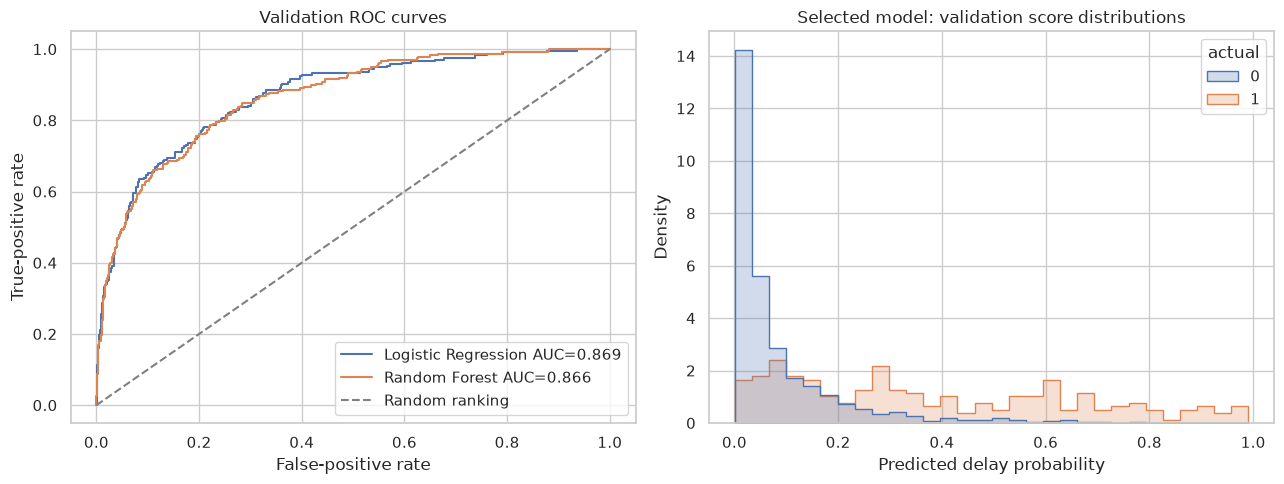

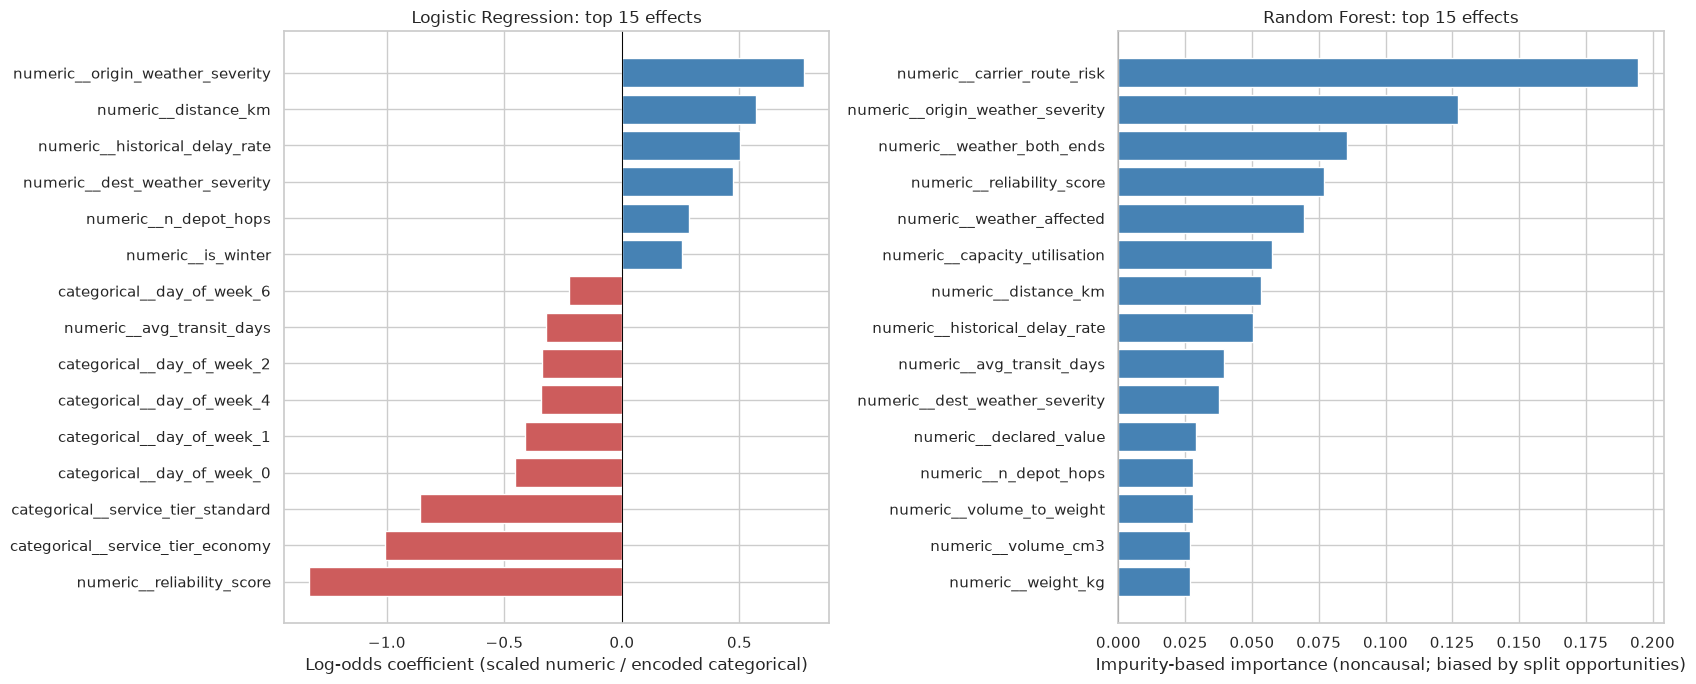

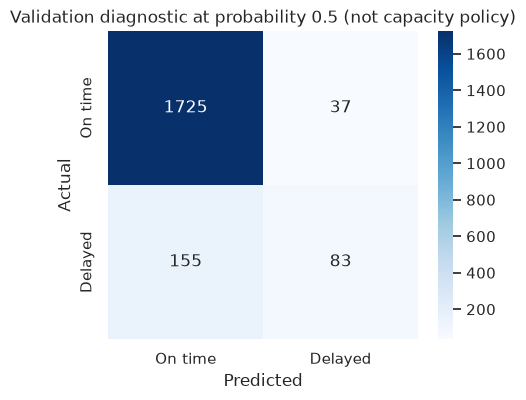

**Diagnostics:** mean selected risk is 0.381 for actual delays and 0.084 for on-time shipments. Distribution overlap explains unavoidable false positives/negatives. At the illustrative 0.5 threshold the confusion matrix is TN=1725, FP=37, FN=155, TP=83; this threshold is not the top-15% intervention rule.

**Observed leading features:** reliability_score has the largest absolute LR coefficient (-1.331 per training-standard-deviation increase), consistent with higher supplied reliability lowering conditional predicted delay log-odds. The forest relies most on numeric__carrier_route_risk: 0.194; numeric__origin_weather_severity: 0.127. Those unsigned importance scores indicate predictive reliance, not direction or causality. Correlated risk/weather inputs can redistribute both coefficient and importance credit.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for family, prob in family_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, prob)
    axes[0].plot(fpr, tpr, label=f'{family} AUC={roc_auc_score(y_val, prob):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Random ranking')
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate', title='Validation ROC curves')
axes[0].legend()
score_frame = pd.DataFrame({'risk': best_prob, 'actual': y_val.to_numpy()})
sns.histplot(data=score_frame, x='risk', hue='actual', bins=30, stat='density', common_norm=False, element='step', ax=axes[1])
axes[1].set(title='Selected model: validation score distributions', xlabel='Predicted delay probability')
fig.tight_layout()
show_figure('model_roc_score_distribution')

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
importance_tables = {}
for ax, (family, (_, search)) in zip(axes, family_winners.items()):
    fitted = search.best_estimator_
    names = fitted.named_steps['preprocess'].get_feature_names_out()
    classifier = fitted.named_steps['model']
    if isinstance(classifier, LogisticRegression):
        values = classifier.coef_[0]
        effect = 'Log-odds coefficient (scaled numeric / encoded categorical)'
    else:
        values = classifier.feature_importances_
        effect = 'Impurity-based importance (noncausal; biased by split opportunities)'
    table = pd.DataFrame({'feature': names, 'effect': values})
    table['absolute_effect'] = table.effect.abs()
    table = table.sort_values('absolute_effect', ascending=False)
    importance_tables[family] = records(table)
    top = table.head(15).sort_values('effect')
    ax.barh(top.feature, top.effect, color=np.where(top.effect >= 0, 'steelblue', 'indianred'))
    ax.axvline(0, color='black', linewidth=0.7)
    ax.set(title=family + ': top 15 effects', xlabel=effect)
fig.tight_layout()
show_figure('model_top15_feature_effects')
report['feature_effects'] = importance_tables
predicted_05 = (best_prob >= 0.5).astype(int)
cm = confusion_matrix(y_val, predicted_05, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On time', 'Delayed'], yticklabels=['On time', 'Delayed'], ax=ax)
ax.set(title='Validation diagnostic at probability 0.5 (not capacity policy)', xlabel='Predicted', ylabel='Actual')
show_figure('model_confusion_threshold_05')
report['diagnostics'] = {'confusion_threshold_05': cm.tolist(), 'mean_risk_on_time': float(score_frame.loc[score_frame.actual.eq(0), 'risk'].mean()),
                         'mean_risk_delayed': float(score_frame.loc[score_frame.actual.eq(1), 'risk'].mean())}
answer(f'**Diagnostics:** mean selected risk is {score_frame.loc[score_frame.actual.eq(1), "risk"].mean():.3f} for actual delays and {score_frame.loc[score_frame.actual.eq(0), "risk"].mean():.3f} for on-time shipments. Distribution overlap explains unavoidable false positives/negatives. At the illustrative 0.5 threshold the confusion matrix is TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}; this threshold is not the top-15% intervention rule.')
lr_effects = pd.DataFrame(importance_tables['Logistic Regression'])
reliability_effect = lr_effects.loc[lr_effects.feature.eq('numeric__reliability_score'), 'effect'].iloc[0]
rf_effects = pd.DataFrame(importance_tables['Random Forest']).head(2)
answer(f'**Observed leading features:** reliability_score has the largest absolute LR coefficient ({reliability_effect:+.3f} per training-standard-deviation increase), consistent with higher supplied reliability lowering conditional predicted delay log-odds. The forest relies most on ' + '; '.join(f'{row.feature}: {row.effect:.3f}' for row in rf_effects.itertuples()) + '. Those unsigned importance scores indicate predictive reliance, not direction or causality. Correlated risk/weather inputs can redistribute both coefficient and importance credit.')

**Interpretation.** A ROC curve above the diagonal indicates better-than-random discrimination; the displayed AUC quantifies it. Score overlap means ranking cannot perfectly separate shipments. LR coefficient signs describe conditional log-odds changes after scaling/encoding, not causal effects; correlated inputs can redistribute coefficient magnitude. Forest impurity importance is unsigned and can favour continuous/high-cardinality inputs; it is not directly comparable to LR coefficient magnitude. The selected model's validation Brier score and average precision are in the comparison table: ROC-AUC alone does not establish calibration, and class weighting can shift calibration. No accuracy-only claim is made.

---
# SECTION 8 - Business Impact *(12 marks)*

,policy,flagged,delays_captured_or_expected,capture_rate,potential_gross_avoided_cost_gbp
0,Model top 15%,300,151.0,0.634454,6795.0
1,Random same capacity (expectation),300,35.7,0.150000,1606.5


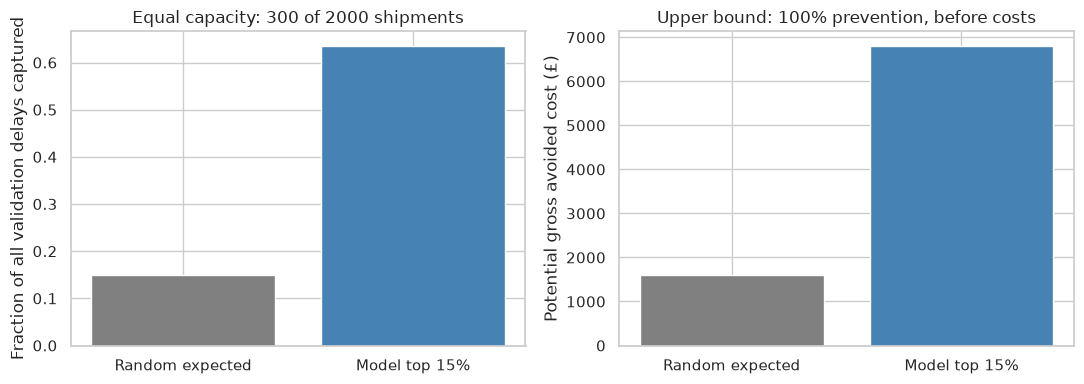

**Held-out business impact:** flagging exactly 300/2,000 shipments captures 151/238 delays (63.4%), versus 35.7 delays (15.0%) in expectation under random selection. This is 4.23× random capture, a 48.4 percentage-point improvement. Flag precision is 50.3%; 149 flags are on-time and 87 delays are missed. At £45 per fully prevented delay, the potential gross avoided cost is £6,795 versus £1,606.50 random expectation; incremental upper bound £5,188.50.

In [16]:
validation = master.loc[val_index, ['shipment_id', 'route_id', 'carrier_id', 'service_tier', 'is_delayed']].copy()
validation['predicted_risk'] = best_prob
ranked = validation.sort_values(['predicted_risk', 'shipment_id'], ascending=[False, True], kind='mergesort').copy()
n_validation = len(ranked)
k = int(np.floor(0.15 * n_validation))
flagged_ids = set(ranked.head(k).shipment_id)
validation['flagged_top15'] = validation.shipment_id.isin(flagged_ids)
ranked['flagged_top15'] = ranked.shipment_id.isin(flagged_ids)
total_delays = int(ranked.is_delayed.sum())
captured = int(ranked.head(k).is_delayed.sum())
capture_rate = captured / total_delays
expected_random_delays = (k / n_validation) * total_delays
random_capture = k / n_validation
policy = {'population': n_validation, 'capacity_fraction': 0.15, 'flagged': k,
          'actual_delays': total_delays, 'captured_delays': captured, 'capture_rate': capture_rate,
          'flag_precision': captured / k, 'false_positive_flags': k - captured,
          'missed_delays': total_delays - captured, 'random_expected_captured': expected_random_delays,
          'random_expected_capture_rate': random_capture, 'capture_lift': capture_rate / random_capture,
          'capture_percentage_point_improvement': capture_rate - random_capture,
          'model_potential_gross_avoided_cost_gbp': captured * 45,
          'random_expected_potential_gross_avoided_cost_gbp': expected_random_delays * 45,
          'incremental_potential_gross_avoided_cost_gbp': (captured - expected_random_delays) * 45,
          'assumed_prevention_fraction': 1.0, 'cost_per_prevented_delay_gbp': 45,
          'interpretation': 'Upper-bound gross scenario; 100% prevention; intervention costs excluded, not realised savings.'}
display(pd.DataFrame([
    {'policy': 'Model top 15%', 'flagged': k, 'delays_captured_or_expected': captured, 'capture_rate': capture_rate, 'potential_gross_avoided_cost_gbp': captured * 45},
    {'policy': 'Random same capacity (expectation)', 'flagged': k, 'delays_captured_or_expected': expected_random_delays, 'capture_rate': random_capture, 'potential_gross_avoided_cost_gbp': expected_random_delays * 45}
]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(['Random expected', 'Model top 15%'], [random_capture, capture_rate], color=['grey', 'steelblue'])
axes[0].set(ylabel='Fraction of all validation delays captured', title=f'Equal capacity: {k} of {n_validation} shipments')
axes[1].bar(['Random expected', 'Model top 15%'], [expected_random_delays * 45, captured * 45], color=['grey', 'steelblue'])
axes[1].set(ylabel='Potential gross avoided cost (£)', title='Upper bound: 100% prevention, before costs')
fig.tight_layout()
show_figure('business_top15_policy')
validation.to_csv('validation_predictions.csv', index=False)
report['policy'] = policy
answer(f'**Held-out business impact:** flagging exactly {k:,}/{n_validation:,} shipments captures {captured}/{total_delays} delays ({capture_rate:.1%}), versus {expected_random_delays:.1f} delays ({random_capture:.1%}) in expectation under random selection. This is {capture_rate/random_capture:.2f}× random capture, a {(capture_rate-random_capture)*100:.1f} percentage-point improvement. Flag precision is {captured/k:.1%}; {k-captured} flags are on-time and {total_delays-captured} delays are missed. At £45 per fully prevented delay, the potential gross avoided cost is £{captured*45:,.0f} versus £{expected_random_delays*45:,.2f} random expectation; incremental upper bound £{(captured-expected_random_delays)*45:,.2f}.')

**Business recommendation.** Rank by predicted risk descending and use shipment ID ascending to break ties; choose `floor(0.15 × n)` so capacity is never exceeded. Random policy values are exact expectations at the same capacity, not a favourable random draw. The preceding results quantify better prioritisation, not actual delay prevention. £45 per captured delay is a **potential gross avoided cost** upper bound assuming every intervention prevents a delay, before intervention costs. No net or realised saving is established.

Operations should pilot the frozen ranking policy with human review, record intervention type/cost and matured outcomes, and randomise a suitable comparison to estimate incremental prevention. Avoid automatically upgrading every flag without a cost/effectiveness assessment. Monitor the displaced opportunities from false-positive flags and customer harm from missed delays. Do not extrapolate the validation currency total directly to monthly savings without population, cost and intervention-effect assumptions.

---
## 8.2 - Save Your Model for Deployment

In [17]:
import joblib
# Contract: engineered DataFrame, not raw CSV rows. This artifact was fitted on training only.
selected_numeric, selected_categorical = feature_sets[selected_key[1]]
required_columns = selected_numeric + selected_categorical
feature_contract = [{'column': col, 'type': 'numeric; missing=np.nan' if col in selected_numeric else 'categorical string; missing=np.nan'} for col in required_columns]
display(pd.DataFrame(feature_contract))
joblib.dump(best_model, 'model.pkl')
loaded_model = joblib.load('model.pkl')
reloaded_prob = loaded_model.predict_proba(X_val)[:, 1]
np.testing.assert_allclose(reloaded_prob, best_prob, rtol=0, atol=1e-12)
scenario = X_val.iloc[:2].copy()
scenario.loc[:, selected_numeric[0]] = np.nan
scenario.loc[:, 'service_tier'] = '__unseen_service__'
scenario_prob = loaded_model.predict_proba(scenario)[:, 1]
assert np.isfinite(scenario_prob).all() and ((scenario_prob >= 0) & (scenario_prob <= 1)).all()
report['artifact'] = {'path': 'model.pkl', 'training_only': True, 'interface': 'engineered feature DataFrame; CSV loading, joins and deterministic features outside artifact',
                      'required_columns': feature_contract, 'extra_columns': 'ignored by ColumnTransformer',
                      'unknown_category_policy': 'one-hot all-zero encoding; not evidence of reliable extrapolation',
                      'reload_max_absolute_difference': float(np.max(np.abs(reloaded_prob - best_prob))),
                      'missing_unseen_scenario_probabilities': scenario_prob.tolist()}
print('Saved and reloaded model.pkl; identical validation probabilities. Missing numeric/unseen category scenario:', scenario_prob)
answer('**Inference contract:** provide the engineered columns listed above with their original units. Numeric missing values are `np.nan`; categorical values are strings with `np.nan` for missing values. Do not pass `pd.NA` or infinity. The pipeline includes fitted median/mode imputation, optional numeric scaling, one-hot encoding and classification. It does not parse dates, join lookup tables or construct features. Missing required columns are an input error; unseen categories are encoded all-zero rather than crashing. CSV joins and feature generation must follow Sections 4–5 with pickup-available snapshots. The artifact remains fitted only on the training partition, preserving the reported holdout provenance.')

,column,type
0,weight_kg,numeric; missing=np.nan
1,volume_cm3,numeric; missing=np.nan
2,declared_value,numeric; missing=np.nan
3,is_business,numeric; missing=np.nan
4,distance_km,numeric; missing=np.nan
5,n_depot_hops,numeric; missing=np.nan
6,historical_delay_rate,numeric; missing=np.nan
7,avg_transit_days,numeric; missing=np.nan
8,reliability_score,numeric; missing=np.nan
9,capacity_utilisation,numeric; missing=np.nan


Saved and reloaded model.pkl; identical validation probabilities. Missing numeric/unseen category scenario: [0.29250108 0.04714556]


**Inference contract:** provide the engineered columns listed above with their original units. Numeric missing values are `np.nan`; categorical values are strings with `np.nan` for missing values. Do not pass `pd.NA` or infinity. The pipeline includes fitted median/mode imputation, optional numeric scaling, one-hot encoding and classification. It does not parse dates, join lookup tables or construct features. Missing required columns are an input error; unseen categories are encoded all-zero rather than crashing. CSV joins and feature generation must follow Sections 4–5 with pickup-available snapshots. The artifact remains fitted only on the training partition, preserving the reported holdout provenance.

---
# SECTION 9 - Monitoring for Drift in Production *(5 marks)*

**9.1 Input drift.** Compare each weekly pickup cohort with the frozen training reference and a recent stable four-week cohort; segment by service tier, region and carrier so mix changes are not hidden. Track missing/invalid weights, declared value, volume/weight, lookup coverage, unseen service/day categories, weather match coverage, severity, distance, route historical delay, reliability and capacity utilisation. Weather/season and carrier capacity are particularly likely to shift; snapshot freshness itself needs monitoring.

For numeric fields report medians, quantiles and standardised mean differences, with PSI on fixed training bins and a two-sample KS statistic. For categorical fields report proportions, unseen-category rate, Jensen–Shannon divergence and chi-square tests where expected cell counts support them. Show effect size and sample size alongside p-values; repeated tests and high volume make p-values alone misleading. A practical investigation alert is PSI >0.2 or a key missing/unseen rate rising by 5 percentage points for two weekly cohorts (illustrative operating thresholds, to be calibrated). First investigate ingestion/schema changes and snapshot staleness; inspect drift by segment, do not retrain automatically on a broken feed.

**9.2 Target/performance drift.** Collect actual outcomes only after the promised delivery window and reporting lag have matured; exclude unresolved shipments rather than treating them as on time. Compare weekly cohorts and a rolling four-week window against training/validation prevalence, with Wilson intervals/binomial uncertainty, segmented by tier/carrier/route. Changing delay prevalence is target drift; conditional feature/outcome changes are concept drift and may occur without prevalence change. Track ROC-AUC, average precision, calibration/Brier score, the fixed-capacity top-15% capture and precision, and intervention costs/effectiveness. Use shipment-ID tie-breaking consistently and report counts/uncertainty, especially in sparse segments.

Investigate if matured delay prevalence changes by >3 percentage points, AUC falls >0.05 below the frozen validation reference, or top-15% capture falls >10 percentage points for two adequately sized cohorts (for example at least 100 delayed shipments pooled). These are proposed alert thresholds, not guarantees; bootstrap intervals and seasonal comparisons help distinguish noise. Check label definitions/lag, data integrity, service mix and intervention effects first. Retrain only when sustained degradation has a plausible data/process explanation and enough representative matured labels; validate a challenger on later untouched cohorts before controlled promotion, and retain a rollback artifact. Interventions themselves change outcomes, so post-deployment capture does not by itself identify causal benefit. Log policy/version/intervention assignment and maintain an ethical comparison where feasible.

---
# EXTENSION *(10 marks)*

**E1 — Route-level risk clustering (5 marks).** Cluster supplied route attributes plus **training-only** shipment summaries. Compare `k=2…6` with silhouette score on standardised numeric profiles; refit only the selected clustering. Outcome summaries never enter the shipment predictor and no validation label enters these profiles. Clusters are descriptive similarity groups, not proven operational causes.

**E2 — SHAP (5 marks).** Explain the ten actual highest-risk validation shipments, using the selected frozen model, a training-derived background and transformed feature names. Additivity is checked on positive-class **probability** output. Explanations describe the model, not causal effects.

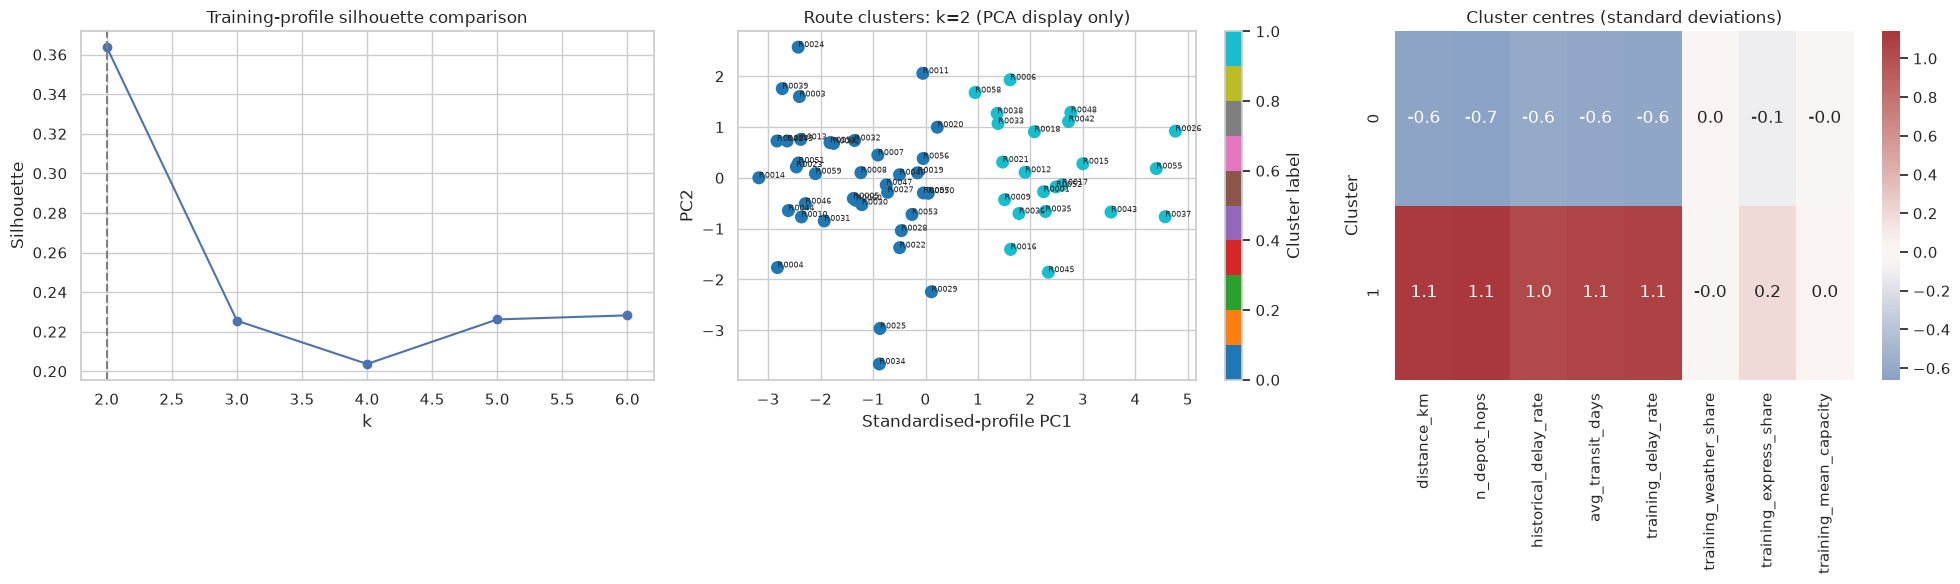

,k,silhouette,inertia
0,2,0.363747,273.827023
1,3,0.225528,233.041101
2,4,0.203683,200.925225
3,5,0.226185,176.890132
4,6,0.228240,159.385728


,cluster,routes,training_shipments,training_delays,minimum_route_training_n,mean_distance_km,mean_depot_hops,mean_historical_delay_rate,mean_transit_days,mean_weather_share,mean_capacity,pooled_training_delay_rate
0,0,38,5049,354,103,241.263158,1.578947,0.131734,2.080526,0.288687,0.757849,0.070113
1,1,22,2951,599,107,531.909091,3.000000,0.244268,3.003636,0.288001,0.758318,0.202982


,route_id,origin_region,dest_region,cluster,training_n,training_delay_rate
1,R0002,Scotland,Yorkshire,0,124,0.120968
2,R0003,South_West,Midlands,0,134,0.022388
3,R0004,London,South_East,0,125,0.056000
4,R0005,Midlands,North_East,0,124,0.072581
6,R0007,South_East,Midlands,0,134,0.111940
7,R0008,North_West,South_West,0,147,0.074830
9,R0010,Yorkshire,Scotland,0,138,0.108696
10,R0011,North_East,Wales,0,117,0.076923
12,R0013,South_East,South_West,0,146,0.034247
13,R0014,North_East,Yorkshire,0,129,0.015504


**Route clustering result:** k=2 maximises the compared silhouette scores. Cluster 1 has the highest pooled training delay rate (20.3%, 599/2951 shipments across 22 routes), mean distance 532 km, mean depot hops 3.0, and supplied historical delay rate 24.4%. Compare the standardised centre heatmap to identify whether long corridors, handoffs, weather exposure or capacity are shared weaknesses; investigate those mechanisms rather than treating cluster labels as causes. The smallest route in that cluster has 107 training shipments. Sparse route rates remain uncertain; missing profiles use route-level medians, and the small 60-route sample makes cluster boundaries sensitive to scaling and feature choice. Duplicate/correlated route measures can overweight a concept. These are descriptive training profiles, not independent validation of network weaknesses.

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

train_profile_rows = master.loc[train_index].copy()
train_profile_rows['express_flag'] = train_profile_rows.service_tier.eq('express').astype(int)
training_route_summary = train_profile_rows.groupby('route_id', observed=True).agg(
    training_n=('is_delayed', 'size'), training_delays=('is_delayed', 'sum'),
    training_delay_rate=('is_delayed', 'mean'), training_weather_share=('weather_affected', 'mean'),
    training_express_share=('express_flag', 'mean'), training_mean_capacity=('capacity_utilisation', 'mean'))
route_profiles = routes.merge(training_route_summary, on='route_id', how='left', validate='one_to_one')
route_profiles['training_n'] = route_profiles.training_n.fillna(0).astype(int)
route_profiles['training_delays'] = route_profiles.training_delays.fillna(0).astype(int)
cluster_features = route_fields + ['training_delay_rate', 'training_weather_share', 'training_express_share', 'training_mean_capacity']
# Route attributes are supplied static inputs; any outcome-derived summary is training-only.
cluster_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
cluster_scaler = StandardScaler()
cluster_matrix = cluster_scaler.fit_transform(cluster_imputer.fit_transform(route_profiles[cluster_features]))
k_comparison = []
cluster_candidates = {}
for candidate_k in range(2, 7):
    candidate = KMeans(n_clusters=candidate_k, n_init=20, random_state=RANDOM_STATE)
    labels = candidate.fit_predict(cluster_matrix)
    cluster_candidates[candidate_k] = candidate
    k_comparison.append({'k': candidate_k, 'silhouette': silhouette_score(cluster_matrix, labels), 'inertia': candidate.inertia_})
k_comparison = pd.DataFrame(k_comparison)
chosen_k = int(k_comparison.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0].k)
cluster_model = cluster_candidates[chosen_k]
route_profiles['cluster'] = cluster_model.labels_
cluster_summary = route_profiles.groupby('cluster', observed=True).agg(
    routes=('route_id', 'size'), training_shipments=('training_n', 'sum'), training_delays=('training_delays', 'sum'),
    minimum_route_training_n=('training_n', 'min'), mean_distance_km=('distance_km', 'mean'),
    mean_depot_hops=('n_depot_hops', 'mean'), mean_historical_delay_rate=('historical_delay_rate', 'mean'),
    mean_transit_days=('avg_transit_days', 'mean'), mean_weather_share=('training_weather_share', 'mean'),
    mean_capacity=('training_mean_capacity', 'mean')).reset_index()
cluster_summary['pooled_training_delay_rate'] = cluster_summary.training_delays / cluster_summary.training_shipments
coordinates = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(cluster_matrix)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].plot(k_comparison.k, k_comparison.silhouette, marker='o')
axes[0].axvline(chosen_k, linestyle='--', color='grey')
axes[0].set(title='Training-profile silhouette comparison', xlabel='k', ylabel='Silhouette')
scatter = axes[1].scatter(coordinates[:, 0], coordinates[:, 1], c=route_profiles.cluster, cmap='tab10', s=70)
for i, row in route_profiles.iterrows():
    axes[1].annotate(row.route_id, (coordinates[i, 0], coordinates[i, 1]), fontsize=6)
axes[1].set(title=f'Route clusters: k={chosen_k} (PCA display only)', xlabel='Standardised-profile PC1', ylabel='PC2')
fig.colorbar(scatter, ax=axes[1], label='Cluster label')
centres = pd.DataFrame(cluster_model.cluster_centers_, columns=cluster_features)
sns.heatmap(centres, cmap='vlag', center=0, annot=True, fmt='.1f', ax=axes[2])
axes[2].set(title='Cluster centres (standard deviations)', ylabel='Cluster')
fig.tight_layout()
show_figure('extension_route_clusters')
display(k_comparison)
display(cluster_summary)
display(route_profiles[['route_id', 'origin_region', 'dest_region', 'cluster', 'training_n', 'training_delay_rate']].sort_values(['cluster', 'route_id']))
risky_cluster = cluster_summary.sort_values('pooled_training_delay_rate', ascending=False).iloc[0]
report['clustering'] = {'features': cluster_features, 'scaling': 'route-profile median imputation then StandardScaler',
                        'k_comparison': records(k_comparison), 'chosen_k': chosen_k,
                        'cluster_summary': records(cluster_summary), 'route_profiles': records(route_profiles),
                        'outcome_source': 'training partition only; not fed into prediction'}
answer(f'**Route clustering result:** k={chosen_k} maximises the compared silhouette scores. Cluster {int(risky_cluster.cluster)} has the highest pooled training delay rate ({risky_cluster.pooled_training_delay_rate:.1%}, {int(risky_cluster.training_delays)}/{int(risky_cluster.training_shipments)} shipments across {int(risky_cluster.routes)} routes), mean distance {risky_cluster.mean_distance_km:.0f} km, mean depot hops {risky_cluster.mean_depot_hops:.1f}, and supplied historical delay rate {risky_cluster.mean_historical_delay_rate:.1%}. Compare the standardised centre heatmap to identify whether long corridors, handoffs, weather exposure or capacity are shared weaknesses; investigate those mechanisms rather than treating cluster labels as causes. The smallest route in that cluster has {int(risky_cluster.minimum_route_training_n)} training shipments. Sparse route rates remain uncertain; missing profiles use route-level medians, and the small 60-route sample makes cluster boundaries sensitive to scaling and feature choice. Duplicate/correlated route measures can overweight a concept. These are descriptive training profiles, not independent validation of network weaknesses.')

/home/hung/Desktop/FSDS/DSAI/lab/Coursework/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### SHAP rank 1: SH0006009
Predicted delay probability **0.9906** = baseline **0.1029** + summed contributions **+0.8877**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.375274
8,numeric__reliability_score,-1.532824,0.218159
11,numeric__dest_weather_severity,2.351587,0.146331
13,numeric__weather_both_ends,5.865000,0.107796
4,numeric__distance_km,0.879968,0.064960
20,categorical__service_tier_standard,1.000000,-0.042531
6,numeric__historical_delay_rate,1.045570,0.037524
5,numeric__n_depot_hops,1.135427,0.037348
21,categorical__day_of_week_0,1.000000,-0.033982
18,categorical__service_tier_economy,0.000000,0.028335


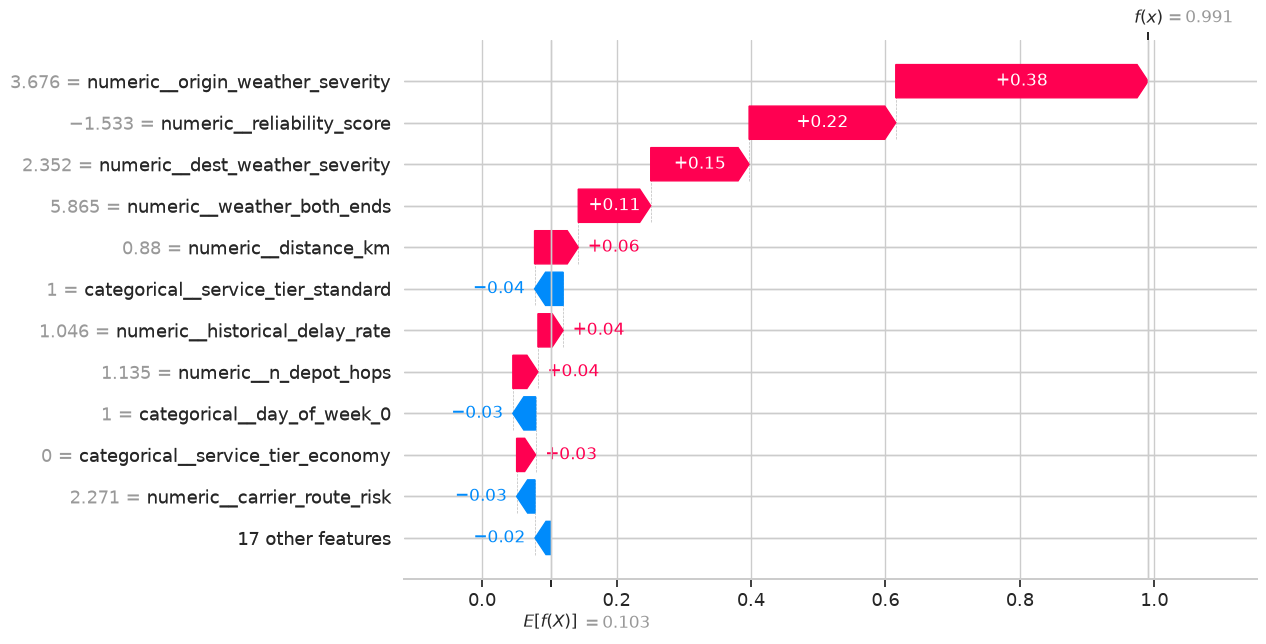

**Largest upward drivers:** numeric__origin_weather_severity (+0.375); numeric__reliability_score (+0.218); numeric__dest_weather_severity (+0.146). **Largest downward drivers:** categorical__service_tier_standard (-0.043); categorical__day_of_week_0 (-0.034); numeric__carrier_route_risk (-0.027). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 2: SH0004068
Predicted delay probability **0.9765** = baseline **0.1029** + summed contributions **+0.8736**. Actual label 0 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,2.320818,0.255126
8,numeric__reliability_score,-1.154668,0.187978
13,numeric__weather_both_ends,5.865000,0.128148
11,numeric__dest_weather_severity,0.978798,0.069824
4,numeric__distance_km,0.806901,0.062734
18,categorical__service_tier_economy,0.000000,0.054506
5,numeric__n_depot_hops,1.135427,0.051771
20,categorical__service_tier_standard,0.000000,0.043557
14,numeric__is_winter,1.425693,0.038851
12,numeric__weather_affected,1.566123,-0.023204


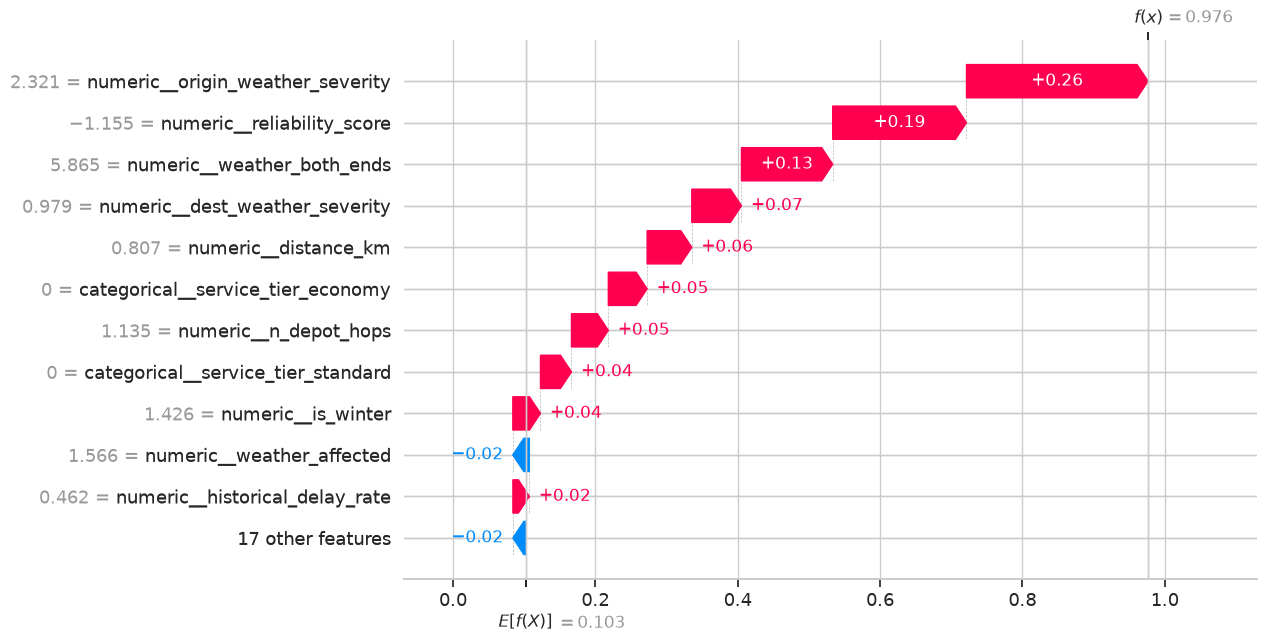

**Largest upward drivers:** numeric__origin_weather_severity (+0.255); numeric__reliability_score (+0.188); numeric__weather_both_ends (+0.128). **Largest downward drivers:** numeric__weather_affected (-0.023); numeric__avg_transit_days (-0.018); numeric__capacity_utilisation (-0.015). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 3: SH0006549
Predicted delay probability **0.9715** = baseline **0.1029** + summed contributions **+0.8686**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.378150
13,numeric__weather_both_ends,5.865000,0.176947
11,numeric__dest_weather_severity,2.351587,0.151881
8,numeric__reliability_score,-1.154668,0.090490
1,numeric__volume_cm3,4.035251,0.071239
5,numeric__n_depot_hops,1.135427,0.057769
20,categorical__service_tier_standard,0.000000,0.043605
18,categorical__service_tier_economy,1.000000,-0.040120
4,numeric__distance_km,0.514630,0.033822
21,categorical__day_of_week_0,1.000000,-0.033418


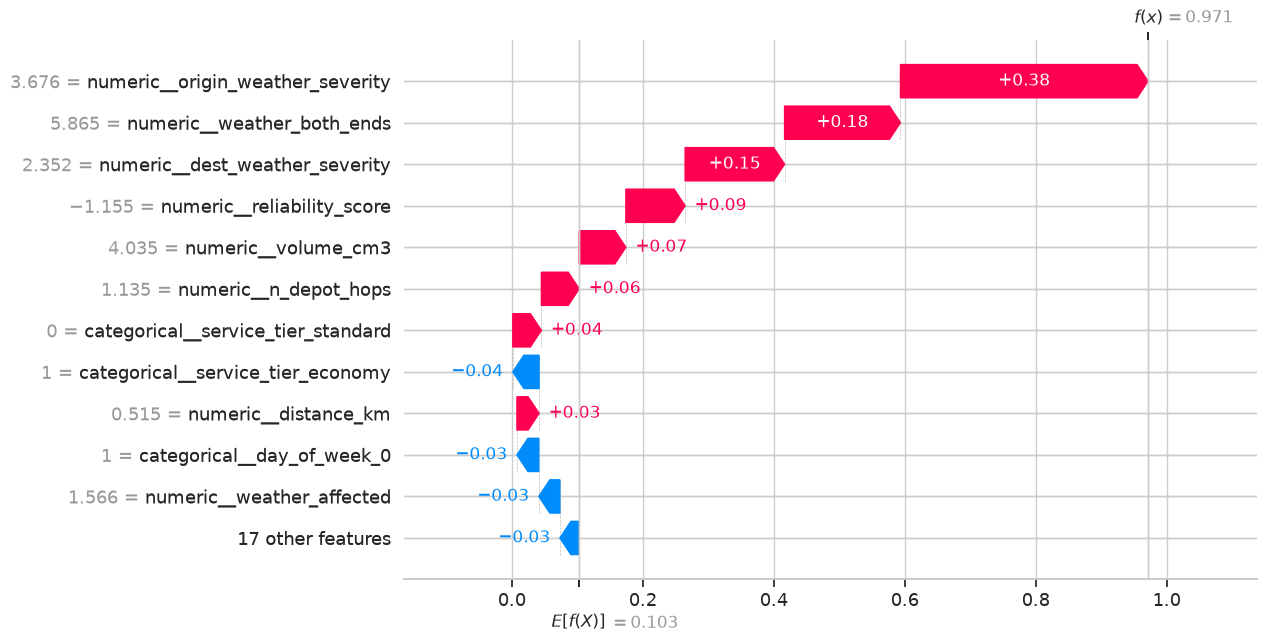

**Largest upward drivers:** numeric__origin_weather_severity (+0.378); numeric__weather_both_ends (+0.177); numeric__dest_weather_severity (+0.152). **Largest downward drivers:** categorical__service_tier_economy (-0.040); categorical__day_of_week_0 (-0.033); numeric__weather_affected (-0.032). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 4: SH0003958
Predicted delay probability **0.9711** = baseline **0.1029** + summed contributions **+0.8681**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,2.320818,0.306997
8,numeric__reliability_score,-1.532824,0.301426
13,numeric__weather_both_ends,5.865000,0.112616
11,numeric__dest_weather_severity,2.351587,0.101686
6,numeric__historical_delay_rate,1.070143,0.057318
22,categorical__day_of_week_1,1.000000,-0.051249
5,numeric__n_depot_hops,1.135427,0.040602
18,categorical__service_tier_economy,1.000000,-0.037267
4,numeric__distance_km,0.806901,0.034386
12,numeric__weather_affected,1.566123,-0.032063


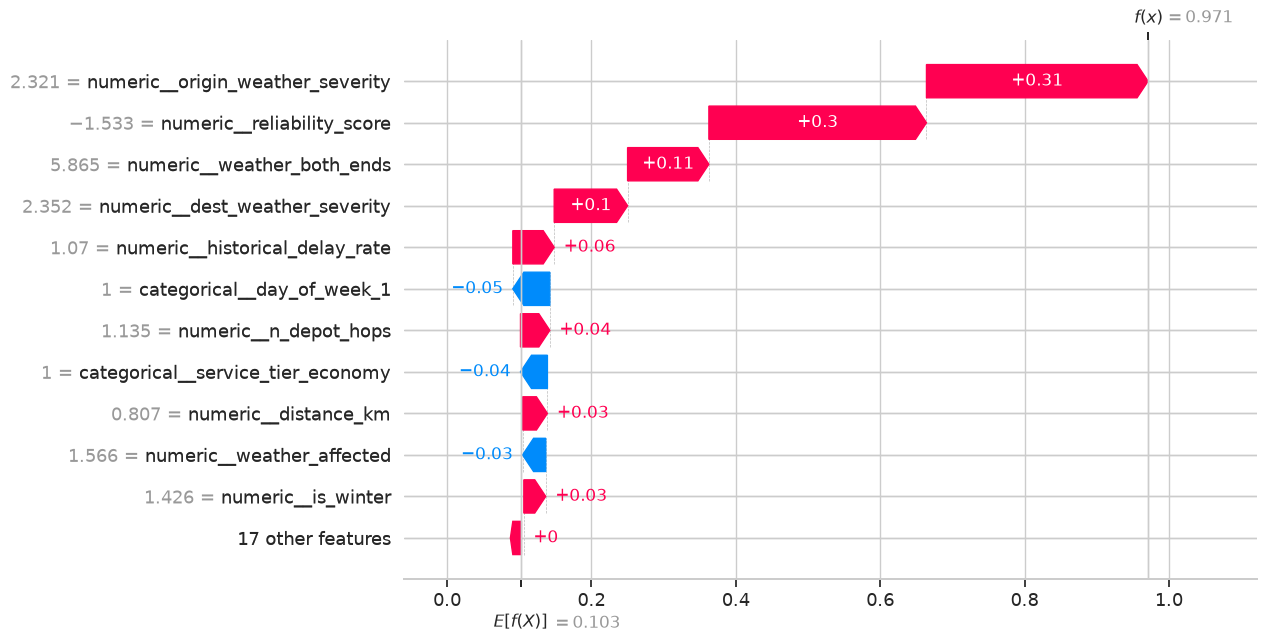

**Largest upward drivers:** numeric__origin_weather_severity (+0.307); numeric__reliability_score (+0.301); numeric__weather_both_ends (+0.113). **Largest downward drivers:** categorical__day_of_week_1 (-0.051); categorical__service_tier_economy (-0.037); numeric__weather_affected (-0.032). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 5: SH0006254
Predicted delay probability **0.9636** = baseline **0.1029** + summed contributions **+0.8607**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.437020
11,numeric__dest_weather_severity,2.351587,0.183518
8,numeric__reliability_score,-1.154668,0.143965
13,numeric__weather_both_ends,5.865000,0.137978
20,categorical__service_tier_standard,1.000000,-0.057708
22,categorical__day_of_week_1,1.000000,-0.048198
5,numeric__n_depot_hops,1.135427,0.041487
6,numeric__historical_delay_rate,0.387856,0.040810
4,numeric__distance_km,0.551164,0.031528
18,categorical__service_tier_economy,0.000000,0.028443


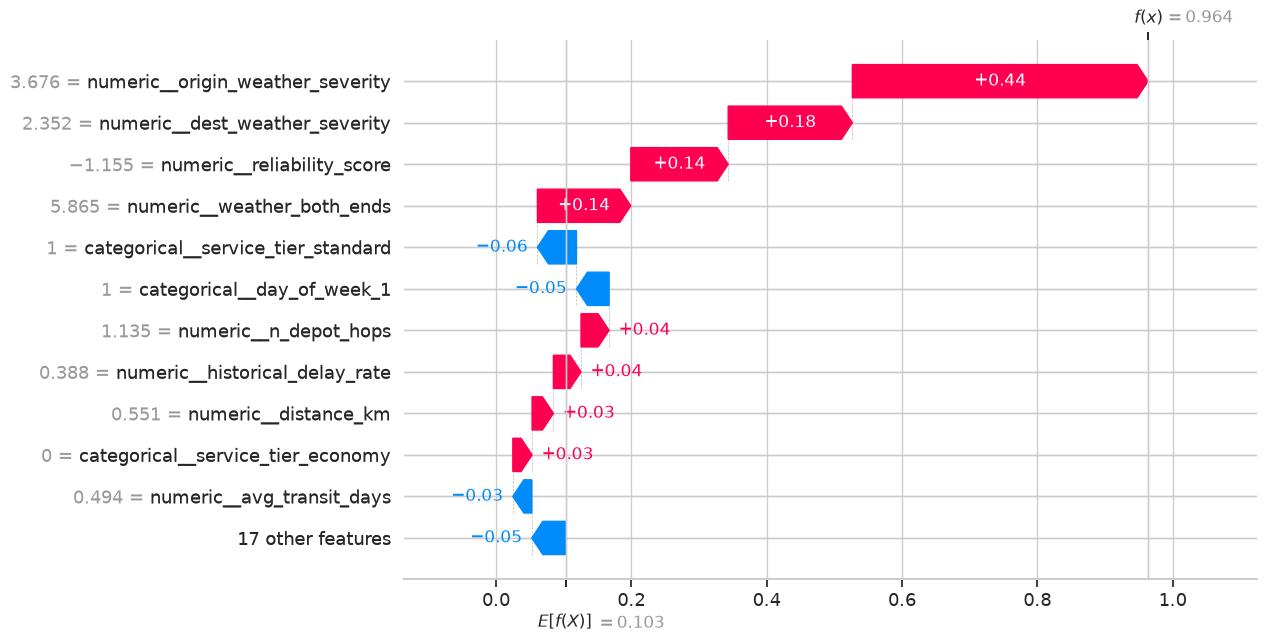

**Largest upward drivers:** numeric__origin_weather_severity (+0.437); numeric__dest_weather_severity (+0.184); numeric__reliability_score (+0.144). **Largest downward drivers:** categorical__service_tier_standard (-0.058); categorical__day_of_week_1 (-0.048); numeric__avg_transit_days (-0.028). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 6: SH0007186
Predicted delay probability **0.9628** = baseline **0.1029** + summed contributions **+0.8599**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.382360
8,numeric__reliability_score,-1.532824,0.321806
4,numeric__distance_km,1.628912,0.115350
7,numeric__avg_transit_days,1.748289,-0.060277
5,numeric__n_depot_hops,1.135427,0.040016
20,categorical__service_tier_standard,0.000000,0.035843
6,numeric__historical_delay_rate,0.859097,0.029884
18,categorical__service_tier_economy,0.000000,0.027806
14,numeric__is_winter,1.425693,0.024857
9,numeric__capacity_utilisation,1.342585,-0.019740


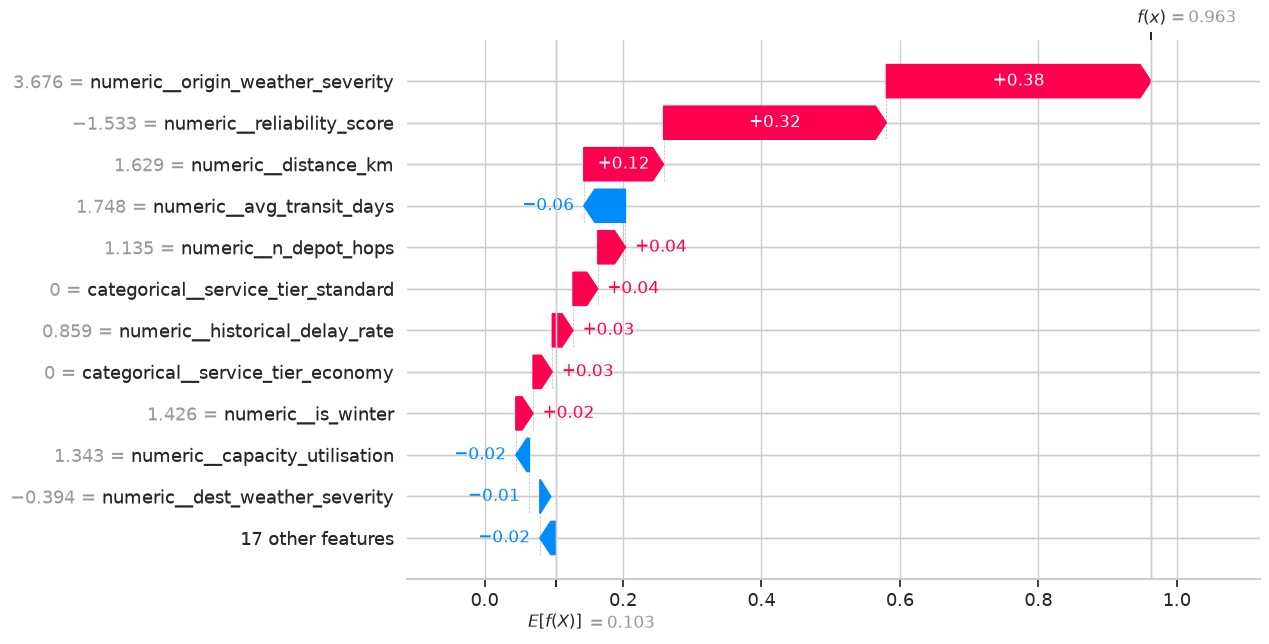

**Largest upward drivers:** numeric__origin_weather_severity (+0.382); numeric__reliability_score (+0.322); numeric__distance_km (+0.115). **Largest downward drivers:** numeric__avg_transit_days (-0.060); numeric__capacity_utilisation (-0.020); numeric__dest_weather_severity (-0.015). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 7: SH0001058
Predicted delay probability **0.9392** = baseline **0.1029** + summed contributions **+0.8363**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
8,numeric__reliability_score,-1.154668,0.205258
13,numeric__weather_both_ends,5.865000,0.174621
6,numeric__historical_delay_rate,2.284383,0.167770
4,numeric__distance_km,2.134297,0.133026
10,numeric__origin_weather_severity,0.965497,0.106304
11,numeric__dest_weather_severity,0.978798,0.079306
7,numeric__avg_transit_days,2.220893,-0.074165
14,numeric__is_winter,1.425693,0.069131
20,categorical__service_tier_standard,1.000000,-0.060194
17,numeric__carrier_route_risk,2.953503,-0.046098


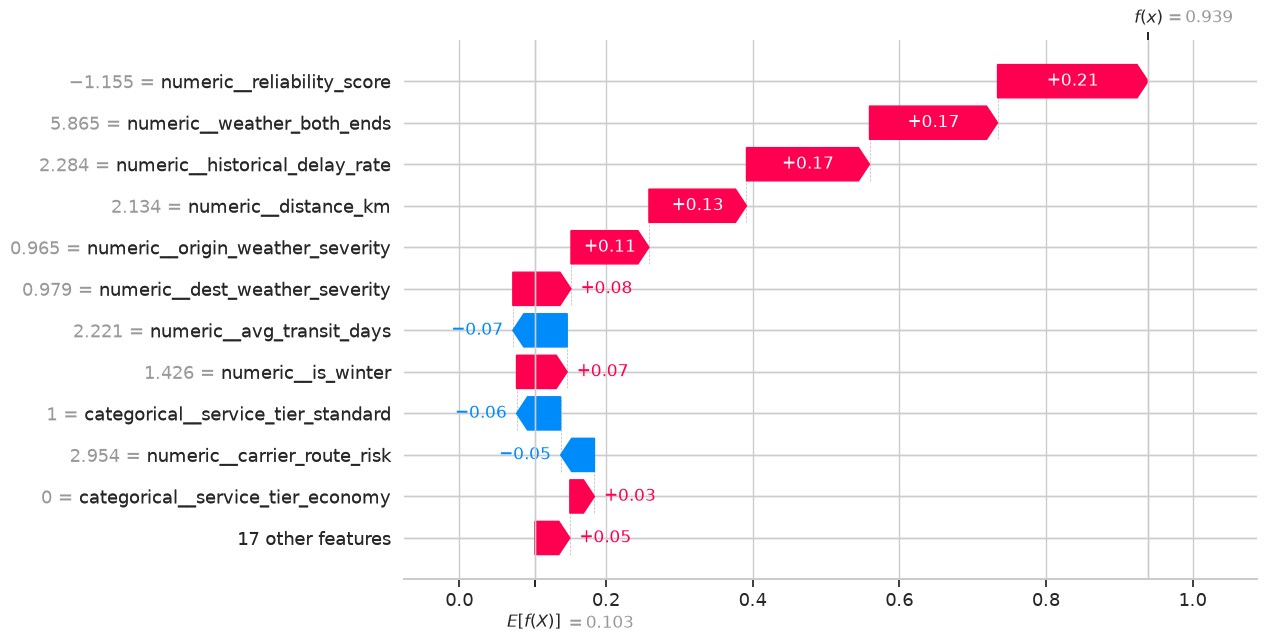

**Largest upward drivers:** numeric__reliability_score (+0.205); numeric__weather_both_ends (+0.175); numeric__historical_delay_rate (+0.168). **Largest downward drivers:** numeric__avg_transit_days (-0.074); categorical__service_tier_standard (-0.060); numeric__carrier_route_risk (-0.046). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 8: SH0005982
Predicted delay probability **0.9343** = baseline **0.1029** + summed contributions **+0.8313**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.445646
11,numeric__dest_weather_severity,3.724376,0.247906
8,numeric__reliability_score,-1.154668,0.234628
13,numeric__weather_both_ends,5.865000,0.131036
4,numeric__distance_km,-1.178104,-0.097243
6,numeric__historical_delay_rate,-0.972381,-0.075734
18,categorical__service_tier_economy,1.000000,-0.075519
7,numeric__avg_transit_days,-1.287278,0.060922
5,numeric__n_depot_hops,-1.395830,-0.048908
20,categorical__service_tier_standard,0.000000,0.042009


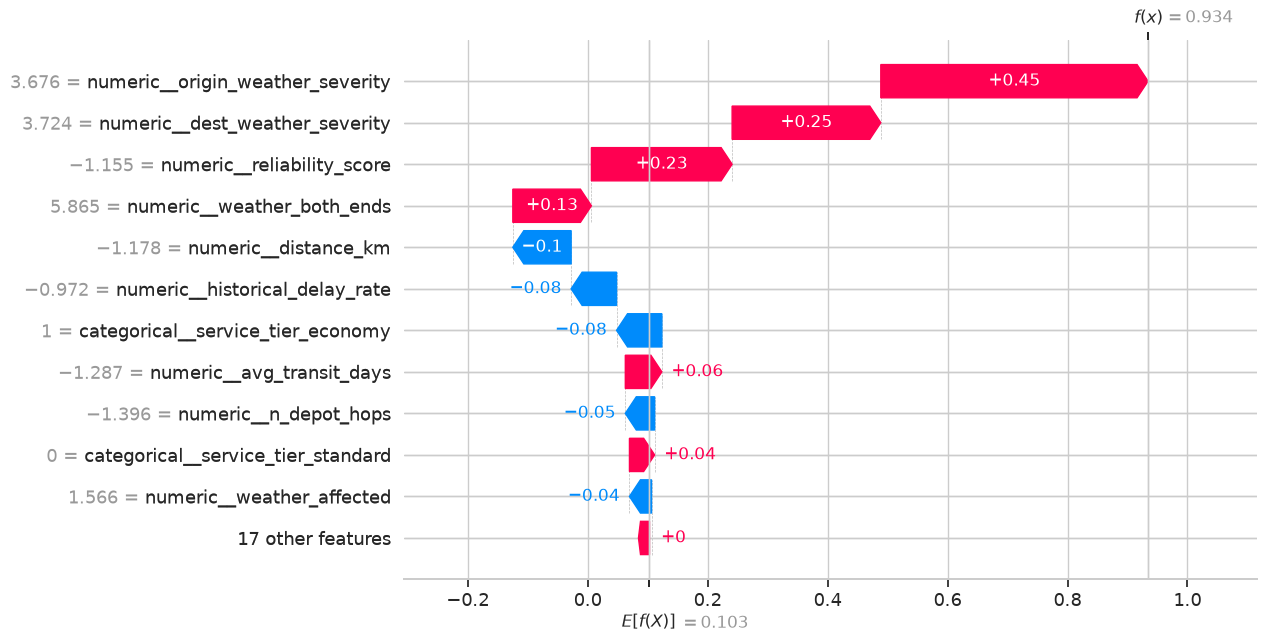

**Largest upward drivers:** numeric__origin_weather_severity (+0.446); numeric__dest_weather_severity (+0.248); numeric__reliability_score (+0.235). **Largest downward drivers:** numeric__distance_km (-0.097); numeric__historical_delay_rate (-0.076); categorical__service_tier_economy (-0.076). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 9: SH0000771
Predicted delay probability **0.9297** = baseline **0.1029** + summed contributions **+0.8267**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.444804
8,numeric__reliability_score,-1.154668,0.214125
5,numeric__n_depot_hops,1.135427,0.055650
14,numeric__is_winter,1.425693,0.045094
20,categorical__service_tier_standard,0.000000,0.044194
4,numeric__distance_km,0.551164,0.039693
6,numeric__historical_delay_rate,0.387856,0.039156
12,numeric__weather_affected,1.566123,-0.029766
18,categorical__service_tier_economy,0.000000,0.024799
11,numeric__dest_weather_severity,-0.393990,-0.021466


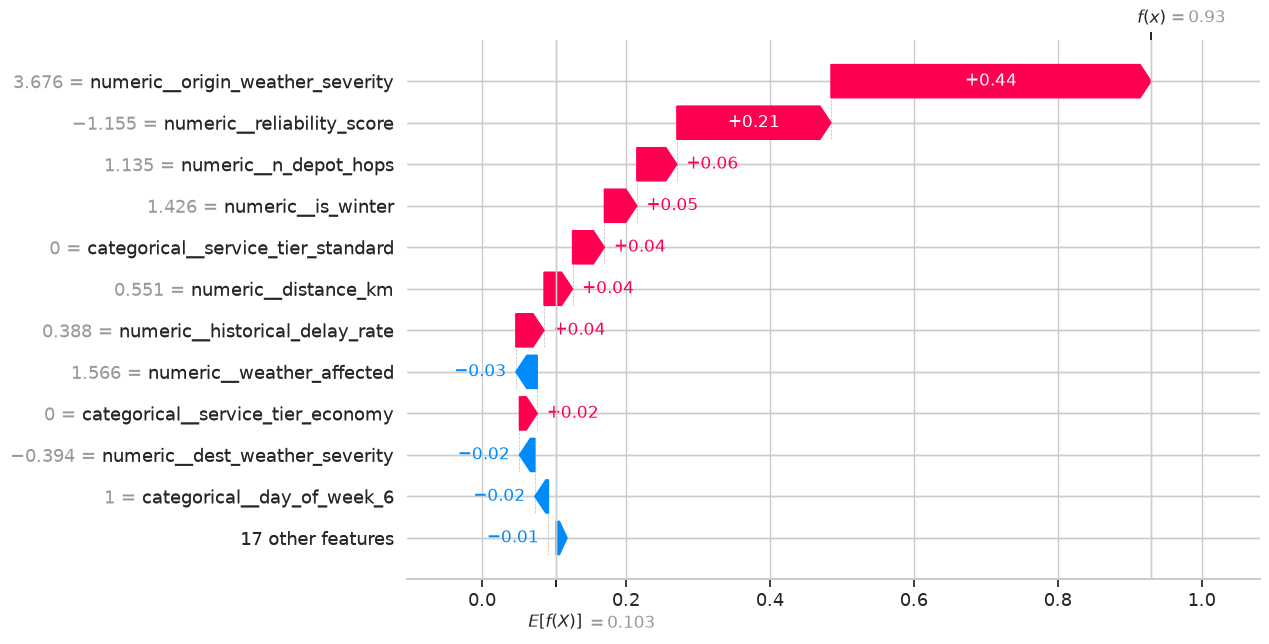

**Largest upward drivers:** numeric__origin_weather_severity (+0.445); numeric__reliability_score (+0.214); numeric__n_depot_hops (+0.056). **Largest downward drivers:** numeric__weather_affected (-0.030); numeric__dest_weather_severity (-0.021); categorical__day_of_week_6 (-0.019). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

### SHAP rank 10: SH0000332
Predicted delay probability **0.9213** = baseline **0.1029** + summed contributions **+0.8184**. Actual label 1 is shown for audit only and was not an explanatory input.

,feature,transformed_value,shap_probability_contribution
10,numeric__origin_weather_severity,3.676139,0.451669
8,numeric__reliability_score,-1.154668,0.168994
13,numeric__weather_both_ends,5.865000,0.158318
11,numeric__dest_weather_severity,0.978798,0.056121
20,categorical__service_tier_standard,1.000000,-0.036716
14,numeric__is_winter,1.425693,0.034498
18,categorical__service_tier_economy,0.000000,0.033646
12,numeric__weather_affected,1.566123,-0.023171
27,categorical__day_of_week_6,1.000000,-0.014025
3,numeric__is_business,-1.365771,-0.012172


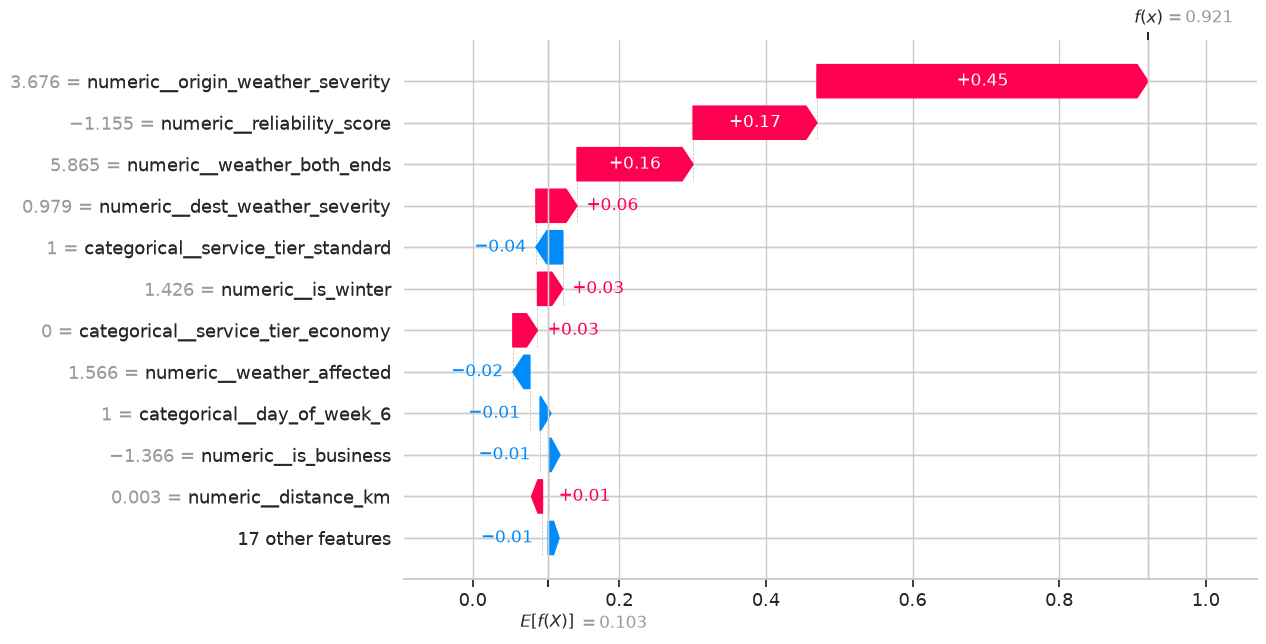

**Largest upward drivers:** numeric__origin_weather_severity (+0.452); numeric__reliability_score (+0.169); numeric__weather_both_ends (+0.158). **Largest downward drivers:** categorical__service_tier_standard (-0.037); numeric__weather_affected (-0.023); categorical__day_of_week_6 (-0.014). Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.

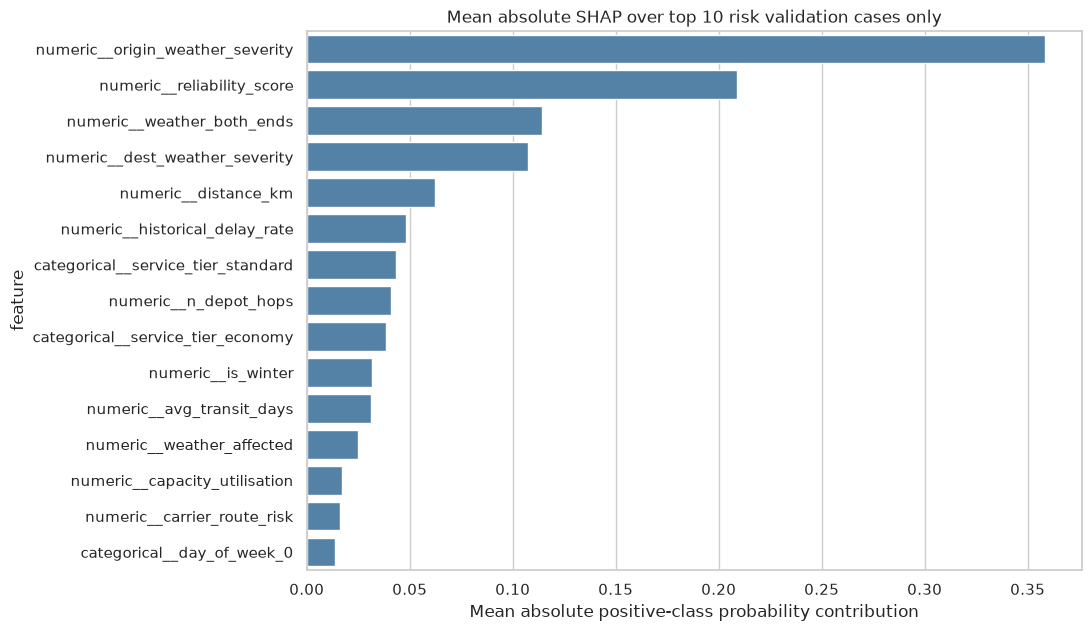

**SHAP scope and limitations:** each table contains all transformed factors for its actual top-risk validation case; the waterfall groups only the less influential factors for display. Numeric values are scaled for an LR winner and unscaled for an RF winner; names retain source feature and encoded category. Positive values raise delay probability relative to this training background; negative values lower it. This is a three-permutation approximation, so allocation can vary with seed/background even though the additive reconstruction is checked. Independent masking can create implausible combinations of correlated weather/route inputs; attributions are model behaviour, not causal effects, and this selected top-ten summary is not global population importance.

In [19]:
import shap

# Explain the same deterministic top-risk order as the intervention policy.
top10_indices = ranked.head(10).index
transformation = best_model.named_steps['preprocess']
classifier = best_model.named_steps['model']
transformed_names = transformation.get_feature_names_out()
background_rows = X_train.sample(n=min(50, len(X_train)), random_state=RANDOM_STATE)
background = transformation.transform(background_rows)
explain_values = transformation.transform(X_val.loc[top10_indices])

def positive_probability(transformed):
    return classifier.predict_proba(transformed)[:, 1]

# Unified permutation SHAP works for LR and RF, on positive-class probability, not log odds.
masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.Explainer(positive_probability, masker, algorithm='permutation',
                         feature_names=transformed_names, seed=RANDOM_STATE)
shap_explanation = explainer(explain_values, max_evals=3 * (2 * explain_values.shape[1] + 1))
local_values = np.asarray(shap_explanation.values)
base_values = np.asarray(shap_explanation.base_values).reshape(-1)
explained_probability = positive_probability(explain_values)
reconstructed_probability = base_values + local_values.sum(axis=1)
np.testing.assert_allclose(reconstructed_probability, explained_probability, rtol=0, atol=1e-6)
np.testing.assert_allclose(explained_probability, ranked.head(10).predicted_risk.to_numpy(), rtol=0, atol=1e-12)
local_results = []
for position, row_index in enumerate(top10_indices):
    shipment_id = master.loc[row_index, 'shipment_id']
    local_table = pd.DataFrame({'feature': transformed_names, 'transformed_value': explain_values[position],
                                'shap_probability_contribution': local_values[position]})
    local_table['absolute_contribution'] = local_table.shap_probability_contribution.abs()
    local_table = local_table.sort_values('absolute_contribution', ascending=False)
    positive = local_table.loc[local_table.shap_probability_contribution > 0].head(3)
    negative = local_table.loc[local_table.shap_probability_contribution < 0].head(3)
    answer(f'### SHAP rank {position+1}: {shipment_id}\nPredicted delay probability **{explained_probability[position]:.4f}** = baseline **{base_values[position]:.4f}** + summed contributions **{local_values[position].sum():+.4f}**. Actual label {int(master.loc[row_index, "is_delayed"])} is shown for audit only and was not an explanatory input.')
    display(local_table.drop(columns='absolute_contribution'))
    shap.plots.waterfall(shap_explanation[position], max_display=12, show=False)
    plt.gcf().set_size_inches(11, 7)
    show_figure(f'extension_shap_{position+1:02d}_{shipment_id}')
    positive_text = '; '.join(f'{r.feature} ({r.shap_probability_contribution:+.3f})' for r in positive.itertuples()) or 'none'
    negative_text = '; '.join(f'{r.feature} ({r.shap_probability_contribution:+.3f})' for r in negative.itertuples()) or 'none'
    answer(f'**Largest upward drivers:** {positive_text}. **Largest downward drivers:** {negative_text}. Contributions are probability-point differences relative to the training-background expectation, not changes caused by intervening on those features.')
    local_results.append({'rank': position+1, 'shipment_id': shipment_id, 'actual': int(master.loc[row_index, 'is_delayed']),
                          'probability': float(explained_probability[position]), 'baseline_probability': float(base_values[position]),
                          'contribution_sum': float(local_values[position].sum()), 'features': records(local_table),
                          'top_positive': records(positive), 'top_negative': records(negative)})
mean_absolute_shap = pd.DataFrame({'feature': transformed_names, 'mean_absolute_shap': np.abs(local_values).mean(axis=0)}).sort_values('mean_absolute_shap', ascending=False)
plt.figure(figsize=(10, 7))
sns.barplot(data=mean_absolute_shap.head(15), x='mean_absolute_shap', y='feature', color='steelblue')
plt.title('Mean absolute SHAP over top 10 risk validation cases only')
plt.xlabel('Mean absolute positive-class probability contribution')
show_figure('extension_shap_top10_summary')
report['shap'] = {'method': 'Permutation SHAP with independent masking on transformed features',
                  'output': 'positive-class probability', 'background_source': '50 random training rows, seed42',
                  'permutations_per_case': 3, 'max_additivity_error': float(np.max(np.abs(reconstructed_probability - explained_probability))),
                  'cases': local_results, 'mean_absolute_top10': records(mean_absolute_shap)}
answer('**SHAP scope and limitations:** each table contains all transformed factors for its actual top-risk validation case; the waterfall groups only the less influential factors for display. Numeric values are scaled for an LR winner and unscaled for an RF winner; names retain source feature and encoded category. Positive values raise delay probability relative to this training background; negative values lower it. This is a three-permutation approximation, so allocation can vary with seed/background even though the additive reconstruction is checked. Independent masking can create implausible combinations of correlated weather/route inputs; attributions are model behaviour, not causal effects, and this selected top-ten summary is not global population importance.')

## Reproducibility checks and exported evidence

The following small checks exercise the notebook's public data/inference contract: unique shipments, target exclusion, alignment/disjoint partitions, inclusive weather boundaries/overlaps/no match, safe ratio handling, probability ranges, exact capacity, persistence and SHAP additivity. They run as part of the notebook, not as an additional modelling experiment. `results.json` is a machine-readable record of observed outputs for the accompanying guide. Personal identity fields and the external submission sheet remain student administrative actions; neither is fabricated.

In [20]:
# Small independently specified weather examples: both boundaries, overlaps, destination and no match.
toy_shipments = pd.DataFrame({
    'pickup_date': pd.to_datetime(['2025-01-01', '2025-01-03', '2025-01-02', '2025-01-04']),
    'origin_region': ['A', 'A', 'A', 'A'], 'dest_region': ['B', 'B', 'B', 'B']})
toy_events = pd.DataFrame({'region': ['A', 'A', 'B'], 'severity': [1, 3, 2],
                           'start_date': pd.to_datetime(['2025-01-01', '2025-01-02', '2025-01-02']),
                           'end_date': pd.to_datetime(['2025-01-03', '2025-01-02', '2025-01-02'])})
toy_result = add_weather(toy_shipments, toy_events)
assert toy_result.origin_weather_severity.tolist() == [1, 1, 3, 0]
assert toy_result.dest_weather_severity.tolist() == [0, 0, 2, 0]
ratio_check = safe_volume_to_weight(pd.Series([10.0, 10.0, 10.0, np.nan, -1.0, 0.0]),
                                   pd.Series([2.0, 0.0, np.nan, 2.0, 1.0, 2.0]))
assert ratio_check.iloc[0] == 5.0 and ratio_check.iloc[5] == 0.0
assert ratio_check.iloc[1:5].isna().all()
assert master.shipment_id.is_unique and not master.duplicated(input_cols).any()
assert 'is_delayed' not in X.columns and not set(EXCLUDE).intersection(X.columns)
assert X.index.equals(y.index) and X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)
assert set(master.loc[train_index, 'shipment_id']).isdisjoint(master.loc[val_index, 'shipment_id'])
assert len(set(train_index) | set(val_index)) == len(master)
assert np.isfinite(best_prob).all() and ((best_prob >= 0) & (best_prob <= 1)).all()
assert not np.isinf(X[enriched_numeric].to_numpy(dtype=float)).any()
assert validation.flagged_top15.sum() == int(np.floor(0.15 * len(validation))) == k
assert ranked.head(k).shipment_id.tolist() == sorted(ranked.head(k).shipment_id.tolist(), key=lambda sid: (-float(validation.set_index('shipment_id').loc[sid, 'predicted_risk']), sid))
np.testing.assert_allclose(loaded_model.predict_proba(X_val)[:, 1], best_prob, rtol=0, atol=1e-12)
report['checks'] = {'shipment_uniqueness': True, 'target_exclusion': True, 'index_alignment': True,
                     'disjoint_partitions': True, 'weather_boundaries_overlap_no_match': True,
                     'finite_or_missing_numeric_features': True, 'safe_zero_missing_ratio': True,
                     'finite_probability_range': True, 'exact_floor_capacity_and_id_tie_break': True,
                     'saved_reload_probability_equality': True, 'missing_and_unseen_inference': True,
                     'shap_additivity': True}
report['figures'] = figure_files
report['versions'] = {'python': platform.python_version(), **{package: importlib.metadata.version(package) for package in
                       ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'joblib', 'shap']}}
report['outputs'] = ['model.pkl', 'validation_predictions.csv', 'results.json'] + figure_files
Path('results.json').write_text(json.dumps(report, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
print('All contract checks passed. Saved results.json, validation_predictions.csv, model.pkl and', len(figure_files), 'figures.')
answer(f'**Final executed conclusion:** frozen {selected_key[0]} ({selected_key[1]}) achieves validation AUC {selected_metrics.val_auc:.4f} and captures {capture_rate:.1%} of validation delays at exactly {k}/{n_validation} interventions. The model is saved with fitted preprocessing and reload equivalence. Route clustering and ten local SHAP explanations are complete above. These results support a monitored pickup-time prioritisation pilot under the snapshot/weather availability assumption, not a claim of proven future performance or realised savings.')

All contract checks passed. Saved results.json, validation_predictions.csv, model.pkl and 19 figures.


**Final executed conclusion:** frozen Logistic Regression (enriched) achieves validation AUC 0.8687 and captures 63.4% of validation delays at exactly 300/2000 interventions. The model is saved with fitted preprocessing and reload equivalence. Route clustering and ten local SHAP explanations are complete above. These results support a monitored pickup-time prioritisation pilot under the snapshot/weather availability assumption, not a claim of proven future performance or realised savings.